# 🏆 World Cup 2026 — Poisson + Monte-Carlo prediction model

Un modèle de prédiction de la Coupe du Monde 2026 construit sur une **régression de Poisson** :
il estime le nombre de buts attendu de chaque équipe à partir de cinq familles de variables, puis
rejoue le tournoi **1 000 fois** par simulation de Monte-Carlo pour en tirer des probabilités de titre.

| Variable | Idée |
|---|---|
| `diff_elo` | écart de classement Elo entre les deux équipes (eloratings.net) |
| `est_domicile` | l'équipe joue-t-elle dans son propre pays |
| `diff_momentum_pts/bp/bc` | forme sur les 10 derniers matchs : points, buts marqués, buts encaissés |
| `penalite_alt` | dette d'oxygène : altitude du stade moins altitude habituelle de l'équipe |
| `choc_thermique` | écart entre la température du stade et le climat habituel de l'équipe |

**Sources de données** — tout est téléchargé à l'exécution, rien n'est stocké dans le dépôt :
[eloratings.net](https://www.eloratings.net) (résultats et Elo par match depuis 2018) et
[Our World in Data](https://ourworldindata.org/grapher/average-annual-surface-temperature) (températures moyennes par pays).

> **Reproductibilité.** Le jeu de données est figé au 5 juin 2026 (veille du tournoi) et la graine
> aléatoire est fixée : deux exécutions donnent exactement les mêmes chiffres, quelle que soit la date
> à laquelle on lance le notebook. Les sources sont pourtant interrogées en direct — c'est la coupure
> temporelle, et non un fichier figé, qui garantit la stabilité.

---

## 1. Configuration

Toutes les dépendances du notebook, importées une seule fois.

In [1]:
import io
import random
import re
from collections import defaultdict
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import poisson
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix

URL_TEAMS = 'https://www.eloratings.net/en.teams.tsv'
URL_WORLD = 'https://www.eloratings.net/World.tsv'
URL_RESULTS = 'https://www.eloratings.net/{annee}_results.tsv'
URL_TEMPERATURES = 'https://ourworldindata.org/grapher/average-annual-surface-temperature.csv?v=1&csvType=full'

FENETRE_MOMENTUM = 10   # nombre de matchs pris en compte pour la forme récente
NB_SIMULATIONS = 1000   # nombre d'univers Monte-Carlo

# Le modèle prédit la Coupe du Monde 2026 : il ne doit donc rien savoir des matchs
# joués pendant ou après le tournoi. On fige le jeu de données à la veille du coup
# d'envoi. Commenter cette ligne (DATE_CUTOFF = None) pour repasser en mode « live ».
DATE_CUTOFF = '2026-06-05'

# Graine fixe : sans elle, 1 000 simulations de Monte-Carlo donnent des chiffres
# légèrement différents à chaque exécution.
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print(f"✅ Environnement prêt. Données figées au {DATE_CUTOFF}, graine {SEED}.")

✅ Environnement prêt. Données figées au 2026-06-05, graine 42.


## 2. Classement Elo du jour

Premier contact avec eloratings.net : le classement mondial en direct, utilisé plus loin comme
point de départ des simulations 2026.

In [2]:
print("🌐 Connexion aux serveurs de eloratings.net en cours...")

# 1. On récupère le fichier "Live" avec les BONS index grâce à ton extrait
# Col 2 (Index 2) = Code (ex: ES), Col 3 (Index 3) = Elo (ex: 2165)
url_world = 'https://www.eloratings.net/World.tsv'
live_data = pd.read_csv(url_world, sep='\t', header=None, usecols=[2, 3], names=['code', 'elo'])
live_data['code'] = live_data['code'].astype(str)

# 2. On lit le dictionnaire des équipes
url_teams = 'https://www.eloratings.net/en.teams.tsv'
# On prévoit large (10 colonnes) pour éviter l'erreur de formatage du site
teams_data_brut = pd.read_csv(url_teams, sep='\t', header=None, names=range(10))
teams_data = teams_data_brut[[0, 1]].rename(columns={0: 'code', 1: 'country'})
teams_data['code'] = teams_data['code'].astype(str)

# 3. La fusion
elo_live_api = pd.merge(teams_data, live_data, on='code')

# 4. On crée notre dictionnaire magique
dict_elo_live_2026 = dict(zip(elo_live_api['country'], elo_live_api['elo']))

# On vérifie si ça a marché en affichant le Top 5 mondial en direct
print("\n✅ Données récupérées avec succès ! Voici le Top 5 mondial aujourd'hui :")
top_5_actuel = sorted(dict_elo_live_2026.items(), key=lambda x: x[1], reverse=True)[:5]
for index, (pays, note) in enumerate(top_5_actuel, start=1):
    print(f"{index}. {pays} : {note} points")

🌐 Connexion aux serveurs de eloratings.net en cours...

✅ Données récupérées avec succès ! Voici le Top 5 mondial aujourd'hui :
1. Spain : 2258 points
2. England : 2182 points
3. Argentina : 2157 points
4. France : 2069 points
5. Portugal : 2005 points


## 3. Construction du jeu de données (2021 → 2026)

Les résultats de chaque année sont servis en TSV sans en-tête. On les empile, on traduit les codes
pays en noms, et on en tire le tableau d'entraînement : date, équipes, score, Elo d'avant-match,
et le pays hôte de la rencontre (qui détermine le vrai avantage du terrain).

In [3]:
print("🔄 Création du Dataset Machine Learning (2021-2026)...")

# 1. Dictionnaire des équipes
url_teams = 'https://www.eloratings.net/en.teams.tsv'
teams_data = pd.read_csv(url_teams, sep='\t', header=None, usecols=[0, 1], names=['code', 'country'])
teams_data['code'] = teams_data['code'].astype(str)

# 2. La Boucle Temporelle (Aspiration de 2021 à 2026)
annees_a_recuperer = range(2021, 2027)
tous_les_matchs = []

for annee in annees_a_recuperer:
    url = f'https://www.eloratings.net/{annee}_results.tsv'
    df_annee = pd.read_csv(url, sep='\t', header=None)
    tous_les_matchs.append(df_annee)

# On fusionne toutes les années en un seul gros tableau brut
matchs_bruts = pd.concat(tous_les_matchs, ignore_index=True)

# 3. Le Grand Renommage
matchs_bruts = matchs_bruts.rename(columns={
    0: 'year', 1: 'month', 2: 'day',
    3: 'code_home', 4: 'code_away',
    5: 'home_score', 6: 'away_score',
    7: 'code_tournoi', 8: 'code_lieu',
    9: 'variation_elo_home',
    10: 'elo_home', 11: 'elo_away',
    12: 'variation_class_home', 13: 'variation_class_away',
    14: 'rang_mondial_home', 15: 'rang_mondial_away'
})

# 4. Nettoyage des dates et des codes
matchs_bruts['date'] = pd.to_datetime(matchs_bruts[['year', 'month', 'day']])
matchs_bruts['code_home'] = matchs_bruts['code_home'].astype(str)
matchs_bruts['code_away'] = matchs_bruts['code_away'].astype(str)
matchs_bruts['code_lieu'] = matchs_bruts['code_lieu'].fillna('').astype(str)

# 5. La Triple Fusion (Traduction des codes)
matchs_traduits = pd.merge(matchs_bruts, teams_data, left_on='code_home', right_on='code', how='left')
matchs_traduits = matchs_traduits.rename(columns={'country': 'home_team'}).drop(columns=['code'])

matchs_traduits = pd.merge(matchs_traduits, teams_data, left_on='code_away', right_on='code', how='left')
matchs_traduits = matchs_traduits.rename(columns={'country': 'away_team'}).drop(columns=['code'])

matchs_traduits = pd.merge(matchs_traduits, teams_data, left_on='code_lieu', right_on='code', how='left')
matchs_traduits['pays_hote'] = matchs_traduits['country'].fillna('')
matchs_traduits.loc[matchs_traduits['pays_hote'] == '', 'pays_hote'] = matchs_traduits['home_team']
matchs_traduits = matchs_traduits.drop(columns=['country', 'code'])

# 6. Structuration pour le Machine Learning
colonnes_finales = [
    'date', 'code_tournoi', 'pays_hote',
    'home_team', 'away_team', 'home_score', 'away_score',
    'elo_home', 'elo_away', 'variation_elo_home',
    'rang_mondial_home', 'rang_mondial_away'
]
df_ml = matchs_traduits[colonnes_finales].copy()

# Suppression des matchs non joués (futurs)
df_ml = df_ml.dropna(subset=['home_score', 'away_score']).copy()

# --- Coupure temporelle : aucun match postérieur au tournoi n'entre dans l'entraînement ---
if DATE_CUTOFF is not None:
    avant = len(df_ml)
    df_ml = df_ml[df_ml['date'] < DATE_CUTOFF].copy()
    print(f"✂️  Coupure au {DATE_CUTOFF} : {avant} → {len(df_ml)} matchs conservés.")

# --- 7. CRÉATION DES VARIABLES PRÉDICTIVES (FEATURES & TARGET) ---

# A. Les "Features" (Ce que l'IA va regarder pour deviner)
df_ml['diff_elo'] = df_ml['elo_home'] - df_ml['elo_away']
df_ml['diff_rang'] = df_ml['rang_mondial_home'] - df_ml['rang_mondial_away']

# On détermine si l'équipe à domicile joue vraiment sur son terrain (1 = Oui, 0 = Non/Neutre)
df_ml['vrai_domicile'] = (df_ml['home_team'] == df_ml['pays_hote']).astype(int)

# B. La "Target" (Ce que l'IA doit apprendre à deviner)
# 1 = Victoire Domicile, 0 = Match Nul, 2 = Victoire Extérieur
def determiner_resultat(row):
    if row['home_score'] > row['away_score']: return 1
    elif row['home_score'] == row['away_score']: return 0
    else: return 2

df_ml['elo_home'] = df_ml['elo_home'] - df_ml['variation_elo_home']
df_ml['elo_away'] = df_ml['elo_away'] - (-df_ml['variation_elo_home']) # Assure-toi que c'est bien la colonne de variation de points !

# Et on calcule la différence sur le VRAI niveau avant le coup de sifflet
df_ml['diff_elo'] = df_ml['elo_home'] - df_ml['elo_away']

df_ml['resultat_match'] = df_ml.apply(determiner_resultat, axis=1)

print(f"✅ Dataset ML prêt ! {len(df_ml)} matchs historiques compilés.")
display(df_ml.tail(10)) # On affiche les derniers matchs joués

🔄 Création du Dataset Machine Learning (2021-2026)...
✂️  Coupure au 2026-06-05 : 6504 → 5764 matchs conservés.
✅ Dataset ML prêt ! 5764 matchs historiques compilés.


,date,code_tournoi,pays_hote,home_team,away_team,home_score,away_score,elo_home,elo_away,variation_elo_home,rang_mondial_home,rang_mondial_away,diff_elo,diff_rang,vrai_domicile,resultat_match
5754,2026-06-04,F,Spain,Northern Ireland,Guinea,1,0,1600,1470,6,64,86,130,-22,0,1
5755,2026-06-04,F,Mexico,Mexico,Serbia,5,1,1867,1742,8,18,36,125,-18,1,1
5756,2026-06-04,F,South Africa,Kenya,Lesotho,1,1,1356,1205,-4,116,156,151,-40,0,0
5757,2026-06-04,F,Turkey,Iran,Mali,2,0,1764,1596,8,28,67,168,-39,0,1
5758,2026-06-04,F,France,France,Ivory Coast,1,2,2082,1677,-19,3,47,405,-44,1,2
5759,2026-06-04,F,United States,Czechia,Guatemala,3,1,1733,1514,7,35,82,219,-47,0,1
5760,2026-06-04,F,Cambodia,Cambodia,Bhutan,4,0,844,637,5,203,228,207,-25,1,1
5761,2026-06-04,F,Andorra,Andorra,Liechtenstein,2,0,1076,904,5,175,198,172,-23,1,1
5762,2026-06-04,DJB,Maldives,Maldives,Pakistan,0,3,835,813,-35,210,204,22,6,1,2
5763,2026-06-04,SQ,Qatar,Yemen,Lebanon,2,0,1151,1332,44,160,141,-181,19,0,1


## 4. Momentum : la forme sur 10 matchs

On bascule le tableau en format long (une ligne par équipe et par match) pour calculer, à chaque
date, les points et les buts des 10 rencontres précédentes. Le `.shift(1)` est essentiel : sans lui,
le résultat du match courant entrerait dans ses propres variables explicatives — une fuite de données
qui gonflerait artificiellement la performance du modèle.

In [4]:
print("🔥 Calcul du Momentum et des statistiques récentes...")

# =====================================================================
# 1. CRÉATION DU FORMAT LONG (Vision centrée sur l'équipe)
# =====================================================================
# Pour calculer l'historique d'une équipe, on doit séparer les matchs à domicile et à l'extérieur
# pour créer une timeline unique par équipe.

df_home = df_ml[['date', 'home_team', 'home_score', 'away_score']].copy()
df_home = df_home.rename(columns={'home_team': 'team', 'home_score': 'buts_pour', 'away_score': 'buts_contre'})

df_away = df_ml[['date', 'away_team', 'away_score', 'home_score']].copy()
df_away = df_away.rename(columns={'away_team': 'team', 'away_score': 'buts_pour', 'home_score': 'buts_contre'})

# On rassemble tout et on trie chronologiquement
df_long = pd.concat([df_home, df_away]).sort_values(['team', 'date']).reset_index(drop=True)

# Calcul des points virtuels pris sur chaque match (Victoire=3, Nul=1, Défaite=0)
conditions_pts = [
    (df_long['buts_pour'] > df_long['buts_contre']),
    (df_long['buts_pour'] == df_long['buts_contre'])
]
df_long['pts_match'] = np.select(conditions_pts, [3, 1], default=0)

# =====================================================================
# 2. CALCUL DES STATISTIQUES GLISSANTES (Les 10 derniers matchs)
# =====================================================================
# L'astuce magique ici est le .shift(1) : il force l'ordinateur à s'arrêter
# au match PRÉCÉDENT, pour ne pas inclure le score du match du jour dans le calcul !

fenetre = 10 # On regarde les 10 derniers matchs (Méthodologie Goldman Sachs)

grouped = df_long.groupby('team')

# Somme glissante des points, buts marqués et encaissés
df_long['pts_10m'] = grouped['pts_match'].transform(lambda x: x.shift(1).rolling(window=fenetre, min_periods=1).sum())
df_long['bp_10m'] = grouped['buts_pour'].transform(lambda x: x.shift(1).rolling(window=fenetre, min_periods=1).sum())
df_long['bc_10m'] = grouped['buts_contre'].transform(lambda x: x.shift(1).rolling(window=fenetre, min_periods=1).sum())

# Nettoyage : Si c'est le tout premier match historique d'une équipe, on met des 0
df_long = df_long.fillna(0)

# On ne garde que les colonnes utiles pour la fusion
df_features = df_long[['date', 'team', 'pts_10m', 'bp_10m', 'bc_10m']]

# =====================================================================
# 3. RÉINTÉGRATION DANS LE DATASET PRINCIPAL (df_ml)
# =====================================================================
# A. On colle les stats récentes de l'équipe à Domicile
df_ml = pd.merge(df_ml, df_features, left_on=['date', 'home_team'], right_on=['date', 'team'], how='left')
df_ml = df_ml.rename(columns={'pts_10m': 'home_pts_10m', 'bp_10m': 'home_bp_10m', 'bc_10m': 'home_bc_10m'}).drop(columns=['team'])

# B. On colle les stats récentes de l'équipe à l'Extérieur
df_ml = pd.merge(df_ml, df_features, left_on=['date', 'away_team'], right_on=['date', 'team'], how='left')
df_ml = df_ml.rename(columns={'pts_10m': 'away_pts_10m', 'bp_10m': 'away_bp_10m', 'bc_10m': 'away_bc_10m'}).drop(columns=['team'])

# C. Nettoyage final des valeurs nulles éventuelles
df_ml = df_ml.fillna(0)

# =====================================================================
# 4. CRÉATION DES DIFFÉRENCES (Pour le modèle Poisson)
# =====================================================================
# L'IA comprend mieux les écarts ("La France a pris 5 points de plus que l'Argentine sur ses 10 derniers matchs")
df_ml['diff_momentum_pts'] = df_ml['home_pts_10m'] - df_ml['away_pts_10m']
df_ml['diff_momentum_bp'] = df_ml['home_bp_10m'] - df_ml['away_bp_10m']
df_ml['diff_momentum_bc'] = df_ml['home_bc_10m'] - df_ml['away_bc_10m']

print("✅ Momentum intégré avec succès !")
# On affiche un petit extrait pour vérifier
display(df_ml[['date', 'home_team', 'away_team', 'diff_momentum_pts', 'diff_momentum_bp', 'diff_momentum_bc']].tail(5))

🔥 Calcul du Momentum et des statistiques récentes...
✅ Momentum intégré avec succès !


,date,home_team,away_team,diff_momentum_pts,diff_momentum_bp,diff_momentum_bc
5783,2026-06-04,Czechia,Guatemala,7.0,8.0,-5.0
5784,2026-06-04,Cambodia,Bhutan,1.0,8.0,-5.0
5785,2026-06-04,Andorra,Liechtenstein,0.0,0.0,-18.0
5786,2026-06-04,Maldives,Pakistan,5.0,6.0,-9.0
5787,2026-06-04,Yemen,Lebanon,-5.0,6.0,8.0


## 5. Photographie du momentum pour 2026

Pour simuler un match futur il faut la forme actuelle de chaque sélection : on prend les 10 derniers
matchs joués par chaque équipe et on les agrège en un dictionnaire.

In [5]:
print("📸 Extraction de la photographie du Momentum pour 2026...")

# =====================================================================
# 1. ISOLER TOUS LES MATCHS JOUÉS JUSQU'À AUJOURD'HUI
# =====================================================================
# On recrée un tableau simple avec tous les matchs de chaque équipe
df_home_live = df_ml[['date', 'home_team', 'home_score', 'away_score']].copy()
df_home_live = df_home_live.rename(columns={'home_team': 'team', 'home_score': 'bp', 'away_score': 'bc'})

df_away_live = df_ml[['date', 'away_team', 'away_score', 'home_score']].copy()
df_away_live = df_away_live.rename(columns={'away_team': 'team', 'away_score': 'bp', 'home_score': 'bc'})

# On fusionne pour avoir le parcours complet de chaque pays
df_live = pd.concat([df_home_live, df_away_live]).dropna()

# Calcul des points du match (3, 1, ou 0)
conditions_pts = [
    (df_live['bp'] > df_live['bc']),
    (df_live['bp'] == df_live['bc'])
]
df_live['pts'] = np.select(conditions_pts, [3, 1], default=0)

# On trie chronologiquement pour être sûr de bien prendre la fin de l'historique
df_live = df_live.sort_values(by=['team', 'date'])

# =====================================================================
# 2. ISOLER LES 10 DERNIERS MATCHS DE CHAQUE PAYS
# =====================================================================
# L'astuce magique : .tail(10) prend les 10 dernières lignes pour chaque groupe (équipe)
derniers_matchs_2026 = df_live.groupby('team').tail(10)

# =====================================================================
# 3. AGRÉGATION ET CRÉATION DU DICTIONNAIRE
# =====================================================================
# On additionne les points et les buts sur ces 10 matchs
stats_live_2026 = derniers_matchs_2026.groupby('team').agg({
    'pts': 'sum',
    'bp': 'sum',
    'bc': 'sum'
}).reset_index()

# On transforme ce tableau en un super-dictionnaire Python !
dict_momentum_2026 = stats_live_2026.set_index('team').to_dict('index')

print(f"✅ Dictionnaire prêt ! La dynamique de {len(dict_momentum_2026)} équipes a été capturée.")

# Petite vérification d'affichage pour voir si tout a fonctionné (ex: l'Argentine)
equipe_test = 'Argentina'
if equipe_test in dict_momentum_2026:
    stats = dict_momentum_2026[equipe_test]
    print(f"\n📊 Momentum actuel de {equipe_test} :")
    print(f"   Points (sur 30 max) : {stats['pts']}")
    print(f"   Buts Marqués        : {stats['bp']}")
    print(f"   Buts Encaissés      : {stats['bc']}")

📸 Extraction de la photographie du Momentum pour 2026...
✅ Dictionnaire prêt ! La dynamique de 229 équipes a été capturée.

📊 Momentum actuel de Argentina :
   Points (sur 30 max) : 25
   Buts Marqués        : 25
   Buts Encaissés      : 4


## 6. Climat : le choc thermique

Une équipe habituée à 8 °C qui joue à 31 °C à Miami subit un coût physiologique. On récupère la
température moyenne annuelle de chaque pays et on en déduit, pour chaque match, l'écart entre le
climat du stade et le climat habituel des deux équipes.

In [6]:
print("🌡️ Connexion furtive à l'API Our World in Data...")

# =====================================================================
# 1. TÉLÉCHARGEMENT ROBUSTE
# =====================================================================
url_temperatures = "https://ourworldindata.org/grapher/average-annual-surface-temperature.csv?v=1&csvType=full"

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36'
}

reponse = requests.get(url_temperatures, headers=headers)

if reponse.status_code == 200:
    print("✅ Le pare-feu a été contourné ! Lecture des données...")
    df_temp_brut = pd.read_csv(io.StringIO(reponse.text))
else:
    raise Exception(f"❌ Échec de connexion (Erreur {reponse.status_code}).")

# =====================================================================
# 2. NETTOYAGE DYNAMIQUE (Anti-Crash & Anti-Doublons)
# =====================================================================
colonnes_minuscules = df_temp_brut.columns.str.lower()
df_temp_brut.columns = colonnes_minuscules

col_pays = next(c for c in colonnes_minuscules if 'entity' in c or 'country' in c)
col_annee = next(c for c in colonnes_minuscules if 'year' in c)
col_temp = next(c for c in colonnes_minuscules if 'temperature' in c or 'temp' in c)

df_temp = df_temp_brut[[col_pays, col_annee, col_temp]].copy()
df_temp = df_temp.rename(columns={col_pays: 'country', col_annee: 'year', col_temp: 'temp'})

# SÉCURITÉ 1 : On supprime les doublons éventuels de l'API pour un même pays/année
df_temp = df_temp.drop_duplicates(subset=['country', 'year'])

# Dictionnaire de secours : La température la plus récente connue par pays
derniere_temp_connue = df_temp.sort_values('year').groupby('country')['temp'].last().to_dict()

# =====================================================================
# 3. SYNCHRONISATION AVEC TON DATASET (SÉCURISÉE)
# =====================================================================
df_ml['year'] = df_ml['date'].dt.year

# SÉCURITÉ 2 : Si tu as relancé la cellule, on efface les anciennes colonnes pour éviter le crash !
colonnes_a_nettoyer = ['temp', 'temp_stade', 'temp_habituelle_home', 'temp_habituelle_away', 'choc_thermique_home', 'choc_thermique_away', 'country']
df_ml = df_ml.drop(columns=[col for col in colonnes_a_nettoyer if col in df_ml.columns])

# --- A. Température du Stade (Pays Hôte) ---
df_ml = pd.merge(df_ml, df_temp, left_on=['pays_hote', 'year'], right_on=['country', 'year'], how='left')
df_ml = df_ml.rename(columns={'temp': 'temp_stade'}).drop(columns=['country'])
df_ml['temp_stade'] = df_ml['temp_stade'].fillna(df_ml['pays_hote'].map(derniere_temp_connue)).fillna(20.0)

# --- B. Température habituelle (Équipe Domicile) ---
df_ml = pd.merge(df_ml, df_temp, left_on=['home_team', 'year'], right_on=['country', 'year'], how='left')
df_ml = df_ml.rename(columns={'temp': 'temp_habituelle_home'}).drop(columns=['country'])
df_ml['temp_habituelle_home'] = df_ml['temp_habituelle_home'].fillna(df_ml['home_team'].map(derniere_temp_connue)).fillna(20.0)

# --- C. Température habituelle (Équipe Extérieur) ---
df_ml = pd.merge(df_ml, df_temp, left_on=['away_team', 'year'], right_on=['country', 'year'], how='left')
df_ml = df_ml.rename(columns={'temp': 'temp_habituelle_away'}).drop(columns=['country'])
df_ml['temp_habituelle_away'] = df_ml['temp_habituelle_away'].fillna(df_ml['away_team'].map(derniere_temp_connue)).fillna(20.0)

# =====================================================================
# 4. LE CALCUL DU CHOC THERMIQUE
# =====================================================================
df_ml['choc_thermique_home'] = np.abs(df_ml['temp_stade'] - df_ml['temp_habituelle_home'])
df_ml['choc_thermique_away'] = np.abs(df_ml['temp_stade'] - df_ml['temp_habituelle_away'])

print("✅ Chocs thermiques calculés avec succès (zéro doublon) !")
display(df_ml[['date', 'pays_hote', 'home_team', 'away_team', 'temp_stade', 'choc_thermique_home', 'choc_thermique_away']].tail(10))

🌡️ Connexion furtive à l'API Our World in Data...
✅ Le pare-feu a été contourné ! Lecture des données...
✅ Chocs thermiques calculés avec succès (zéro doublon) !


,date,pays_hote,home_team,away_team,temp_stade,choc_thermique_home,choc_thermique_away
5778,2026-06-04,Spain,Northern Ireland,Guinea,15.087102,4.912898,11.328746
5779,2026-06-04,Mexico,Mexico,Serbia,21.679186,0.000000,9.456339
5780,2026-06-04,South Africa,Kenya,Lesotho,18.347360,7.449027,6.594347
5781,2026-06-04,Turkey,Iran,Mali,12.884452,6.820655,16.674655
5782,2026-06-04,France,France,Ivory Coast,14.224018,0.000000,5.775982
5783,2026-06-04,United States,Czechia,Guatemala,10.425442,1.346629,13.266231
5784,2026-06-04,Cambodia,Cambodia,Bhutan,27.263230,0.000000,17.501863
5785,2026-06-04,Andorra,Andorra,Liechtenstein,6.479347,0.000000,13.520653
5786,2026-06-04,Maldives,Maldives,Pakistan,20.000000,0.000000,1.464668
5787,2026-06-04,Qatar,Yemen,Lebanon,27.877142,1.582464,10.884575


## 7. Altitude : la dette d'oxygène

Même logique pour l'altitude, avec un détail important : contrairement à l'Elo ou au momentum, cette
variable n'est **pas** symétrique. Jouer à 2 240 m ne pénalise que l'équipe qui n'y est pas habituée —
la pénalité est donc calculée séparément pour chaque camp, et jamais inversée.

In [7]:
print("⛰️ Extraction des altitudes et calcul de la dette d'oxygène...")

# =====================================================================
# 1. NETTOYAGE DE TON TEXTE BRUT (Regex Magic)
# =====================================================================
texte_brut = """Bhutan3,280Nepal3,265Tajikistan3,186Kyrgyzstan2,989Lesotho2,161Andorra1,996Afghanistan1,884Chile1,871China1,840Armenia1,792Greenland1,792Rwanda1,598Mongolia1,580Peru1,555Burundi1,504Georgia1,432Switzerland1,350Ethiopia1,330Iran1,305Lebanon1,250Bolivia1,192Taiwan1,150Turkey1,141Namibia1,141Zambia1,138Ecuador1,117Angola1,112Mexico1,111Uganda1,100Montenegro1,086South Africa1,034Tanzania1,018Botswana1,013Yemen999Zimbabwe961Jordan920Austria910Morocco909Pakistan900Eritrea853Algeria800Kosovo800Malawi779Kenya762United States of America760Guatemala759Costa Rica746Macedonia741Congo-Kinshasa726Laos710Albania708Myanmar702Honduras684Papua New Guinea667Cameroon667Saudi Arabia665Spain660Central African Republic635India621Russian Federation600Argentina595Colombia593Equatorial Guinea577Sudan568Iceland557Chad543Malaysia538Italy538Syria514Israel508Bosnia and Herzegovina500Greece498Slovenia492Canada487Brunei474Niger474Serbia473Guinea472Bulgaria470Haiti470Norway460Slovakia458Venezuela450Uzbekistan450El Salvador442Madagascar442Philippines442Japan438Czech Republic430Congo-Brazzaville430Djibouti430Dominican Republic424Libya423Romania414Somalia410North Korea400Vietnam398Vanuatu398New Zealand388Kazakhstan387Azerbaijan384Nigeria380Gabon377France375Portugal372Indonesia367Panama360Mozambique345Mali343Jamaica340Croatia331Australia330Luxembourg325Egypt321Brazil320Sweden320Iraq312Oman310Swaziland305Nicaragua298Burkina Faso297Thailand287South Korea282Sierra Leone279Mauritania276Benin273Germany263Côte d'Ivoire250Suriname246Tunisia246Liberia243Togo236Turkmenistan230Sri Lanka228Guyana207Ghana190Belgium181Paraguay178Ukraine175Poland173Belize173Belarus170Finland164United Arab Emirates149Hungary143Moldova139Cambodia126Ireland118Lithuania110Uruguay109Cuba108Kuwait108Cyprus91Latvia87Bangladesh85Trinidad and Tobago83United Kingdom75Guinea-Bissau70Senegal69Estonia61Gambia34Denmark34The Netherlands30Qatar28Singapore15Marshall Islands2Kiribati2Tuvalu1.8Maldives1.5"""

# On dit à Python : "Trouve moi du texte (le pays) collé à des chiffres et des virgules (l'altitude)"
# ex: "Switzerland1,350" -> ('Switzerland', '1,350')
regex = re.findall(r'([A-Za-z\s\-\']+|)([\d,\.]+)', texte_brut)

dict_altitude = {}
for pays, alt_str in regex:
    # On retire les virgules (ex: 1,350 -> 1350) et on convertit en nombre
    try:
        alt_float = float(alt_str.replace(',', ''))
        # Petite traduction pour correspondre aux noms Elo
        pays_nettoye = pays.strip()
        if pays_nettoye == 'United States of America': pays_nettoye = 'United States'
        if pays_nettoye == 'Russian Federation': pays_nettoye = 'Russia'
        if pays_nettoye == 'The Netherlands': pays_nettoye = 'Netherlands'

        dict_altitude[pays_nettoye] = alt_float
    except ValueError:
        pass

# =====================================================================
# 2. INTÉGRATION À TON DATASET HISTORIQUE (df_ml)
# =====================================================================
# A. On attache l'altitude au Pays Hôte (Le Stade)
df_ml['alt_stade'] = df_ml['pays_hote'].map(dict_altitude)

# B. On attache l'altitude de l'Équipe Domicile et Extérieur
df_ml['alt_habituelle_home'] = df_ml['home_team'].map(dict_altitude)
df_ml['alt_habituelle_away'] = df_ml['away_team'].map(dict_altitude)

# Nettoyage : Si un petit pays (ex: San Marin) n'est pas dans la liste, on lui met 100m par défaut
df_ml['alt_stade'] = df_ml['alt_stade'].fillna(100.0)
df_ml['alt_habituelle_home'] = df_ml['alt_habituelle_home'].fillna(100.0)
df_ml['alt_habituelle_away'] = df_ml['alt_habituelle_away'].fillna(100.0)

# =====================================================================
# 3. LE CALCUL DE LA PÉNALITÉ D'ALTITUDE
# =====================================================================
# LA RÈGLE D'OR EN MÉDECINE SPORTIVE :
# Jouer plus bas que chez soi ne donne pas de bonus, jouer plus haut donne une pénalité.
# On utilise np.maximum pour ignorer (mettre à 0) les descentes d'altitude.

df_ml['penalite_alt_home'] = np.maximum(0, df_ml['alt_stade'] - df_ml['alt_habituelle_home']) / 1000
df_ml['penalite_alt_away'] = np.maximum(0, df_ml['alt_stade'] - df_ml['alt_habituelle_away']) / 1000

print("✅ Altitudes intégrées et pénalités calculées !")
display(df_ml[['date', 'pays_hote', 'home_team', 'away_team', 'alt_stade', 'penalite_alt_home', 'penalite_alt_away']].tail(10))

⛰️ Extraction des altitudes et calcul de la dette d'oxygène...
✅ Altitudes intégrées et pénalités calculées !


,date,pays_hote,home_team,away_team,alt_stade,penalite_alt_home,penalite_alt_away
5778,2026-06-04,Spain,Northern Ireland,Guinea,660.0,0.560,0.188
5779,2026-06-04,Mexico,Mexico,Serbia,1111.0,0.000,0.638
5780,2026-06-04,South Africa,Kenya,Lesotho,1034.0,0.272,0.000
5781,2026-06-04,Turkey,Iran,Mali,1141.0,0.000,0.798
5782,2026-06-04,France,France,Ivory Coast,375.0,0.000,0.275
5783,2026-06-04,United States,Czechia,Guatemala,760.0,0.660,0.001
5784,2026-06-04,Cambodia,Cambodia,Bhutan,126.0,0.000,0.000
5785,2026-06-04,Andorra,Andorra,Liechtenstein,1996.0,0.000,1.896
5786,2026-06-04,Maldives,Maldives,Pakistan,1.5,0.000,0.000
5787,2026-06-04,Qatar,Yemen,Lebanon,28.0,0.000,0.000


## 8. Le modèle de Poisson

Chaque match fournit **deux** observations : une ligne pour l'équipe qui reçoit, une pour l'adversaire
avec les variables symétriques inversées. On ajuste ensuite une régression de Poisson sur le nombre de
buts, puis on teste le modèle sur un cas extrême (France à La Paz) pour vérifier que la pénalité
d'altitude pèse bien dans le bon sens.

In [8]:
# =====================================================================
# ÉTAPE 1 : PRÉPARATION DU DATASET DE POISSON V3 (L'Ultime)
# =====================================================================
print("⏳ Structuration des données (Elo + Domicile + Momentum + Géographie)...")

# Équipe 1 (Celle qui "reçoit", ou considérée comme "Home" sur terrain neutre)
df_domicile = pd.DataFrame({
    'buts': df_ml['home_score'],
    'diff_elo': df_ml['diff_elo'],
    'est_domicile': df_ml['vrai_domicile'],
    'diff_momentum_pts': df_ml['diff_momentum_pts'],
    'diff_momentum_bp': df_ml['diff_momentum_bp'],
    'diff_momentum_bc': df_ml['diff_momentum_bc'],
    # Nouvelles variables : le fardeau physique de l'équipe 1
    'penalite_alt': df_ml['penalite_alt_home'],
    'choc_thermique': df_ml['choc_thermique_home']
})

# Équipe 2 (L'adversaire)
df_exterieur = pd.DataFrame({
    'buts': df_ml['away_score'],
    'diff_elo': -df_ml['diff_elo'], # On inverse l'Elo
    'est_domicile': 0,              # Ne joue jamais chez elle
    'diff_momentum_pts': -df_ml['diff_momentum_pts'], # On inverse le Momentum
    'diff_momentum_bp': -df_ml['diff_momentum_bp'],
    'diff_momentum_bc': -df_ml['diff_momentum_bc'],
    # ⚠️ Attention ici : on n'inverse PAS l'altitude et la température !
    # C'est une charge qui pèse sur l'équipe 2.
    'penalite_alt': df_ml['penalite_alt_away'],
    'choc_thermique': df_ml['choc_thermique_away']
})

# Fusion pour créer le super-dataset d'entraînement
df_poisson = pd.concat([df_domicile, df_exterieur], ignore_index=True).dropna()

# =====================================================================
# ÉTAPE 2 : ENTRAÎNEMENT DU MODÈLE SURPUISSANT (V3)
# =====================================================================
print("🚀 Entraînement de la Loi de Poisson V3...")

# La formule finale de ton IA : Technique + Forme + Physique
formule = "buts ~ diff_elo + est_domicile + diff_momentum_pts + diff_momentum_bp + diff_momentum_bc + penalite_alt + choc_thermique"
model_poisson = smf.poisson(formule, data=df_poisson).fit()
print(model_poisson.summary())

# =====================================================================
# ÉTAPE 3 : FONCTION DE SIMULATION (Mise à jour Intégrale)
# =====================================================================
def simuler_match_poisson(elo_home, elo_away,
                          mom_pts_home=0, mom_pts_away=0,
                          mom_bp_home=0, mom_bp_away=0,
                          mom_bc_home=0, mom_bc_away=0,
                          pen_alt_home=0, pen_alt_away=0,      # <-- Ajout Altitude
                          choc_therm_home=0, choc_therm_away=0, # <-- Ajout Météo
                          est_terrain_neutre=False, max_buts=10):

    diff_elo_home = elo_home - elo_away
    diff_elo_away = elo_away - elo_home

    diff_mom_pts_home = mom_pts_home - mom_pts_away
    diff_mom_bp_home = mom_bp_home - mom_bp_away
    diff_mom_bc_home = mom_bc_home - mom_bc_away

    avantage_home = 0 if est_terrain_neutre else 1

    # 1. Prédiction des Lambdas avec TOUTES les 7 variables
    df_pred_home = pd.DataFrame({
        'diff_elo': [diff_elo_home], 'est_domicile': [avantage_home],
        'diff_momentum_pts': [diff_mom_pts_home], 'diff_momentum_bp': [diff_mom_bp_home], 'diff_momentum_bc': [diff_mom_bc_home],
        'penalite_alt': [pen_alt_home], 'choc_thermique': [choc_therm_home]
    })
    lambda_home = model_poisson.predict(df_pred_home)[0]

    df_pred_away = pd.DataFrame({
        'diff_elo': [diff_elo_away], 'est_domicile': [0],
        'diff_momentum_pts': [-diff_mom_pts_home], 'diff_momentum_bp': [-diff_mom_bp_home], 'diff_momentum_bc': [-diff_mom_bc_home],
        'penalite_alt': [pen_alt_away], 'choc_thermique': [choc_therm_away]
    })
    lambda_away = model_poisson.predict(df_pred_away)[0]

    # 2. Matrice de Poisson
    prob_home = [poisson.pmf(i, lambda_home) for i in range(max_buts)]
    prob_away = [poisson.pmf(i, lambda_away) for i in range(max_buts)]
    matrice_scores = np.outer(prob_home, prob_away)

    return {
        'lambda_home': lambda_home, 'lambda_away': lambda_away,
        'proba_1': np.sum(np.tril(matrice_scores, -1)),
        'proba_X': np.sum(np.diag(matrice_scores)),
        'proba_2': np.sum(np.triu(matrice_scores, 1)),
        'matrice': matrice_scores
    }

# =====================================================================
# ÉTAPE 4 : EXEMPLE DE PRÉDICTION (Le test extrême)
# =====================================================================
print("\n🔮 Exemple de simulation : France vs Bolivie à La Paz (Altitude extrême)")

# La France est largement supérieure techniquement (2100 vs 1700) et en bonne forme.
# MAIS le match se joue en Bolivie à 3600m d'altitude.
# La France (habituée à 200m) prend une pénalité monstrueuse de 3.4.
# La Bolivie (habituée à 3500m) n'a aucune pénalité.

resultat_test = simuler_match_poisson(
    elo_home=1700, elo_away=2100,  # Bolivie (1700) vs France (2100)
    mom_pts_home=12, mom_pts_away=22,
    mom_bp_home=10, mom_bp_away=20,
    mom_bc_home=10, mom_bc_away=5,
    pen_alt_home=0.0, pen_alt_away=3.4, # <-- Le piège d'altitude pour la France !
    choc_therm_home=0.0, choc_therm_away=5.0,
    est_terrain_neutre=False # La Bolivie joue chez elle
)

print(f"Moyenne de buts Bolivie (λ) : {resultat_test['lambda_home']:.2f}")
print(f"Moyenne de buts France (λ) : {resultat_test['lambda_away']:.2f}")
print(f"➔ Probabilité Victoire Bolivie : {resultat_test['proba_1']:.2%}")
print(f"➔ Probabilité Match Nul : {resultat_test['proba_X']:.2%}")
print(f"➔ Probabilité Victoire France : {resultat_test['proba_2']:.2%}")

score_max = np.unravel_index(np.argmax(resultat_test['matrice']), resultat_test['matrice'].shape)
print(f"🎯 Score exact le plus probable : {score_max[0]} - {score_max[1]}")

⏳ Structuration des données (Elo + Domicile + Momentum + Géographie)...
🚀 Entraînement de la Loi de Poisson V3...
Optimization terminated successfully.
         Current function value: 1.409106
         Iterations 5
                          Poisson Regression Results                          
Dep. Variable:                   buts   No. Observations:                11576
Model:                        Poisson   Df Residuals:                    11568
Method:                           MLE   Df Model:                            7
Date:                Wed, 18 Nov 2026   Pseudo R-squ.:                  0.1310
Time:                        04:10:51   Log-Likelihood:                -16312.
converged:                       True   LL-Null:                       -18771.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                        coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------

## 9. Le tournoi 2026

Les 12 groupes, les trois pays hôtes, les 16 stades avec leur altitude et leur température estivale,
et le camp de base attribué à chaque groupe. Les stades à toit fermé (Dallas, Houston, Atlanta) sont
forcés à 22 °C.

In [9]:
groupes_2026 = {
    'Groupe A': ['Mexico', 'South Africa', 'South Korea', 'Czechia'],
    'Groupe B': ['Canada', 'Bosnia and Herzegovina', 'Qatar', 'Switzerland'],
    'Groupe C': ['Haiti', 'Scotland', 'Brazil', 'Morocco'],
    'Groupe D': ['Australia', 'United States', 'Turkey', 'Paraguay'],
    'Groupe E': ['Ecuador', 'Germany', 'Curaçao', 'Ivory Coast'],
    'Groupe F': ['Netherlands', 'Japan', 'Sweden', 'Tunisia'],
    'Groupe G': ['Iran', 'New Zealand', 'Belgium', 'Egypt'],
    'Groupe H': ['Spain', 'Cape Verde', 'Saudi Arabia', 'Uruguay'],
    'Groupe I': ['France', 'Senegal', 'Iraq', 'Norway'],
    'Groupe J': ['Argentina', 'Algeria', 'Austria', 'Jordan'],
    'Groupe K': ['Portugal', 'Uzbekistan', 'Colombia', 'DR Congo'],
    'Groupe L': ['Ghana', 'England', 'Panama', 'Croatia'],
}

# Seuls les pays hôtes reçoivent le bonus de terrain du modèle
pays_hotes_2026 = ['United States', 'Mexico', 'Canada']

# Altitude (m) et température estivale (°C) des 16 stades
stades_2026 = {
    'Mexico City': {'alt': 2240, 'temp': 24}, 'Guadalajara': {'alt': 1566, 'temp': 26}, 'Monterrey': {'alt': 540, 'temp': 32},
    'Vancouver': {'alt': 10, 'temp': 22}, 'Toronto': {'alt': 75, 'temp': 25},
    'Miami': {'alt': 5, 'temp': 31}, 'Los Angeles': {'alt': 50, 'temp': 24}, 'New York': {'alt': 10, 'temp': 28},
    'Seattle': {'alt': 50, 'temp': 22}, 'Boston': {'alt': 15, 'temp': 26}, 'Philadelphia': {'alt': 10, 'temp': 28},
    'San Francisco': {'alt': 15, 'temp': 20}, 'Kansas City': {'alt': 270, 'temp': 30},
    'Dallas': {'alt': 160, 'temp': 22}, 'Houston': {'alt': 15, 'temp': 22}, 'Atlanta': {'alt': 300, 'temp': 22},  # toits fermés
}

# Camp de base attribué à chaque groupe
villes_groupes_2026 = {
    'Groupe A': 'Mexico City', 'Groupe B': 'Vancouver', 'Groupe C': 'Los Angeles',
    'Groupe D': 'Miami', 'Groupe E': 'New York', 'Groupe F': 'Dallas',
    'Groupe G': 'Seattle', 'Groupe H': 'Atlanta', 'Groupe I': 'Houston',
    'Groupe J': 'Monterrey', 'Groupe K': 'Toronto', 'Groupe L': 'Philadelphia',
}

print(f'✅ {len(groupes_2026)} groupes, {len(stades_2026)} stades, hôtes : {", ".join(pays_hotes_2026)}')

✅ 12 groupes, 16 stades, hôtes : United States, Mexico, Canada


## 10. Simulation de Monte-Carlo du tournoi complet

Le cœur du projet. Plutôt que d'appeler `model.predict()` des centaines de milliers de fois, on extrait
une fois pour toutes les coefficients du modèle et on calcule λ directement — c'est ce qui rend
1 000 tournois complets calculables en quelques secondes.

Chaque univers rejoue les 12 groupes, classe les 8 meilleurs troisièmes, puis déroule l'arbre à
élimination directe jusqu'au sacre. Les matchs nuls en phase finale sont départagés par une
prolongation (Poisson à λ/3) puis, si besoin, par une séance de tirs au but arbitrée par l'écart Elo.

In [10]:
print("🌍 Initialisation du Moteur Monte-Carlo V3 (Elo + Momentum + Géographie)...")

# Fonction utilitaire pour calculer le fardeau physique d'une équipe
def calculer_fardeau_physique(equipe, ville_stade, dict_geo):
    stade_alt = stades_2026[ville_stade]['alt']
    stade_temp = stades_2026[ville_stade]['temp']

    eq_alt = dict_geo.get(equipe, {'alt': 100})['alt']
    eq_temp = dict_geo.get(equipe, {'temp': 20})['temp']

    pen_alt = max(0, stade_alt - eq_alt) / 1000.0
    choc_therm = abs(stade_temp - eq_temp)
    return pen_alt, choc_therm

# Extraction des poids du modèle (À faire UNE SEULE FOIS avant la boucle)
coefs = model_poisson.params

# =====================================================================
# 1. LE RÉSOLVEUR DE MATCHS À ÉLIMINATION DIRECTE (VERSION TURBO)
# =====================================================================
def simuler_match_elimination_rapide(eq1, eq2, ville_stade, dict_elo, dict_momentum, dict_geo, coefs, pays_hotes):
    elo1, elo2 = dict_elo.get(eq1, 1500), dict_elo.get(eq2, 1500)
    mom1, mom2 = dict_momentum.get(eq1, {'pts': 0, 'bp': 0, 'bc': 0}), dict_momentum.get(eq2, {'pts': 0, 'bp': 0, 'bc': 0})

    hote1 = 1 if eq1 in pays_hotes else 0
    hote2 = 1 if eq2 in pays_hotes else 0

    pen_alt_1, choc_1 = calculer_fardeau_physique(eq1, ville_stade, dict_geo)
    pen_alt_2, choc_2 = calculer_fardeau_physique(eq2, ville_stade, dict_geo)

    diff_pts = mom1['pts'] - mom2['pts']
    diff_bp = mom1['bp'] - mom2['bp']
    diff_bc = mom1['bc'] - mom2['bc']

    # --- CALCUL MATHÉMATIQUE DIRECT DE LAMBDA (Ultra-rapide) ---
    log_lam_1 = (coefs['Intercept'] +
                 coefs['diff_elo'] * (elo1 - elo2) +
                 coefs['est_domicile'] * hote1 +
                 coefs['diff_momentum_pts'] * diff_pts +
                 coefs['diff_momentum_bp'] * diff_bp +
                 coefs['diff_momentum_bc'] * diff_bc +
                 coefs['penalite_alt'] * pen_alt_1 +
                 coefs['choc_thermique'] * choc_1)

    log_lam_2 = (coefs['Intercept'] +
                 coefs['diff_elo'] * (elo2 - elo1) +
                 coefs['est_domicile'] * hote2 +
                 coefs['diff_momentum_pts'] * (-diff_pts) +
                 coefs['diff_momentum_bp'] * (-diff_bp) +
                 coefs['diff_momentum_bc'] * (-diff_bc) +
                 coefs['penalite_alt'] * pen_alt_2 +
                 coefs['choc_thermique'] * choc_2)

    lambda_1 = np.exp(log_lam_1)
    lambda_2 = np.exp(log_lam_2)

    # --- JEU DU MATCH ---
    b1, b2 = np.random.poisson(lambda_1), np.random.poisson(lambda_2)
    if b1 > b2: return eq1
    if b2 > b1: return eq2

    if (b1 + np.random.poisson(lambda_1 / 3)) > (b2 + np.random.poisson(lambda_2 / 3)): return eq1
    if (b2 + np.random.poisson(lambda_2 / 3)) > (b1 + np.random.poisson(lambda_1 / 3)): return eq2

    return eq1 if np.random.rand() < (1 / (1 + 10 ** ((elo2 - elo1) / 400))) else eq2

# =====================================================================
# 2. LE MOTEUR DE SIMULATION GLOBAL (VERSION TURBO)
# =====================================================================
def simuler_un_univers_rapide(groupes, dict_elo, dict_momentum, dict_geo, coefs, pays_hotes):
    premiers, deuxiemes, troisiemes = [], [], []
    villes_list = list(stades_2026.keys())

    # --- PHASE 1 : POULES ---
    for nom_groupe, equipes in groupes.items():
        ville_poule = villes_groupes_2026.get(nom_groupe, 'Miami')
        classement = {eq: {'pts': 0, 'diff': 0, 'bp': 0} for eq in equipes}

        for eq1, eq2 in combinations(equipes, 2):
            elo1, elo2 = dict_elo.get(eq1, 1500), dict_elo.get(eq2, 1500)
            mom1, mom2 = dict_momentum.get(eq1, {'pts': 0, 'bp': 0, 'bc': 0}), dict_momentum.get(eq2, {'pts': 0, 'bp': 0, 'bc': 0})
            hote1, hote2 = 1 if eq1 in pays_hotes else 0, 1 if eq2 in pays_hotes else 0

            pen_alt_1, choc_1 = calculer_fardeau_physique(eq1, ville_poule, dict_geo)
            pen_alt_2, choc_2 = calculer_fardeau_physique(eq2, ville_poule, dict_geo)

            diff_pts = mom1['pts'] - mom2['pts']
            diff_bp = mom1['bp'] - mom2['bp']
            diff_bc = mom1['bc'] - mom2['bc']

            lam1 = np.exp(coefs['Intercept'] + coefs['diff_elo']*(elo1-elo2) + coefs['est_domicile']*hote1 +
                          coefs['diff_momentum_pts']*diff_pts + coefs['diff_momentum_bp']*diff_bp + coefs['diff_momentum_bc']*diff_bc +
                          coefs['penalite_alt']*pen_alt_1 + coefs['choc_thermique']*choc_1)

            lam2 = np.exp(coefs['Intercept'] + coefs['diff_elo']*(elo2-elo1) + coefs['est_domicile']*hote2 +
                          coefs['diff_momentum_pts']*(-diff_pts) + coefs['diff_momentum_bp']*(-diff_bp) + coefs['diff_momentum_bc']*(-diff_bc) +
                          coefs['penalite_alt']*pen_alt_2 + coefs['choc_thermique']*choc_2)

            b1, b2 = np.random.poisson(lam1), np.random.poisson(lam2)
            classement[eq1]['bp'] += b1; classement[eq1]['diff'] += (b1 - b2)
            classement[eq2]['bp'] += b2; classement[eq2]['diff'] += (b2 - b1)

            if b1 > b2: classement[eq1]['pts'] += 3
            elif b2 > b1: classement[eq2]['pts'] += 3
            else: classement[eq1]['pts'] += 1; classement[eq2]['pts'] += 1

        trie = sorted(classement.items(), key=lambda x: (x[1]['pts'], x[1]['diff'], x[1]['bp']), reverse=True)
        premiers.append(trie[0][0]); deuxiemes.append(trie[1][0])
        troisiemes.append((trie[2][0], trie[2][1]['pts'], trie[2][1]['diff'], trie[2][1]['bp']))

    meilleurs_troisiemes = [t[0] for t in sorted(troisiemes, key=lambda x: (x[1], x[2], x[3]), reverse=True)[:8]]

    # --- PHASE FINALE ---
    seiziemes = [
        (premiers[0], meilleurs_troisiemes[0]), (deuxiemes[1], deuxiemes[2]), (premiers[3], meilleurs_troisiemes[1]), (deuxiemes[4], deuxiemes[5]),
        (premiers[6], meilleurs_troisiemes[2]), (deuxiemes[7], deuxiemes[8]), (premiers[9], meilleurs_troisiemes[3]), (deuxiemes[10], deuxiemes[11]),
        (premiers[1], meilleurs_troisiemes[4]), (premiers[2], meilleurs_troisiemes[5]), (premiers[4], meilleurs_troisiemes[6]), (premiers[5], meilleurs_troisiemes[7]),
        (premiers[7], deuxiemes[0]), (premiers[8], deuxiemes[3]), (premiers[10], deuxiemes[6]), (premiers[11], deuxiemes[9])
    ]

    huitiemes = [simuler_match_elimination_rapide(m[0], m[1], random.choice(villes_list), dict_elo, dict_momentum, dict_geo, coefs, pays_hotes) for m in seiziemes]
    quarts = [simuler_match_elimination_rapide(huitiemes[i], huitiemes[i+1], random.choice(villes_list), dict_elo, dict_momentum, dict_geo, coefs, pays_hotes) for i in range(0, 16, 2)]
    demies = [simuler_match_elimination_rapide(quarts[i], quarts[i+1], random.choice(villes_list), dict_elo, dict_momentum, dict_geo, coefs, pays_hotes) for i in range(0, 8, 2)]

    finale = [simuler_match_elimination_rapide(demies[0], demies[1], 'New York', dict_elo, dict_momentum, dict_geo, coefs, pays_hotes),
              simuler_match_elimination_rapide(demies[2], demies[3], 'New York', dict_elo, dict_momentum, dict_geo, coefs, pays_hotes)]

    champion = simuler_match_elimination_rapide(finale[0], finale[1], 'New York', dict_elo, dict_momentum, dict_geo, coefs, pays_hotes)

    return premiers + deuxiemes + meilleurs_troisiemes, huitiemes, quarts, demies, finale, champion

# =====================================================================
# 3. LA BOUCLE MONTE-CARLO (MISE À JOUR AVEC COEFS)
# =====================================================================
def lancer_monte_carlo_complet(groupes, dict_elo, dict_momentum, dict_geo, coefs, pays_hotes, nb_simus=1000):
    print(f"🚀 Lancement de {nb_simus} simulations (MODE TURBO ACTIVÉ) ...")

    tracker = defaultdict(lambda: {'16es': 0, '8es': 0, 'Quarts': 0, 'Demies': 0, 'Finale': 0, 'Sacre': 0})

    for i in range(nb_simus):
        # On passe 'coefs' à la place de 'modele_poisson' !
        seiz, huit, quarts, demies, fin, vainqueur = simuler_un_univers_rapide(groupes, dict_elo, dict_momentum, dict_geo, coefs, pays_hotes)

        for eq in seiz: tracker[eq]['16es'] += 1
        for eq in huit: tracker[eq]['8es'] += 1
        for eq in quarts: tracker[eq]['Quarts'] += 1
        for eq in demies: tracker[eq]['Demies'] += 1
        for eq in fin: tracker[eq]['Finale'] += 1
        tracker[vainqueur]['Sacre'] += 1

    print("\n🏆 CHANCES DE GAGNER LA COUPE DU MONDE 2026 🏆")
    print("=" * 75)
    print(f"{'Équipe':<20} | 16es  | 8es   | Quarts | Demies | Finale | 🏆 SACRE")
    print("-" * 75)

    resultats_tries = sorted(tracker.items(), key=lambda x: x[1]['Sacre'], reverse=True)

    for eq, stats in resultats_tries:
        if stats['Sacre'] > 0:
            print(f"{eq:<20} | {(stats['16es']/nb_simus)*100:>4.0f}% | {(stats['8es']/nb_simus)*100:>4.0f}% | {(stats['Quarts']/nb_simus)*100:>5.0f}% | {(stats['Demies']/nb_simus)*100:>5.0f}% | {(stats['Finale']/nb_simus)*100:>5.0f}% | {(stats['Sacre']/nb_simus)*100:>5.1f}%")

    return {eq: {k: v / nb_simus for k, v in stats.items()} for eq, stats in tracker.items()}

print("🌍 Création du Dictionnaire Géographique des Équipes...")

dict_geo_equipes_2026 = {}

# On parcourt toutes les équipes présentes dans tes poules 2026
toutes_les_equipes_2026 = [eq for poule in groupes_2026.values() for eq in poule]

for equipe in toutes_les_equipes_2026:
    # On va chercher l'altitude (créée lors de l'étape du texte brut). Sinon 100m par défaut.
    alt = dict_altitude.get(equipe, 100.0) if 'dict_altitude' in globals() else 100.0

    # On va chercher la température (créée via l'API Our World in Data). Sinon 20°C par défaut.
    temp = derniere_temp_connue.get(equipe, 20.0) if 'derniere_temp_connue' in globals() else 20.0

    dict_geo_equipes_2026[equipe] = {'alt': alt, 'temp': temp}

print(f"✅ Dictionnaire créé avec succès pour {len(dict_geo_equipes_2026)} équipes !")

# L'Elo de référence doit lui aussi dater d'avant le tournoi : le classement récupéré
# en section 2 est celui d'aujourd'hui. On reconstitue donc l'Elo de chaque sélection à
# la date de coupure, à partir des Elo d'avant-match contenus dans les résultats.
if DATE_CUTOFF is not None:
    elo_long_2026 = pd.concat([
        df_ml[['date', 'home_team', 'elo_home']].rename(columns={'home_team': 'team', 'elo_home': 'rating'}),
        df_ml[['date', 'away_team', 'elo_away']].rename(columns={'away_team': 'team', 'elo_away': 'rating'}),
    ]).dropna().sort_values('date')
    dict_elo_2026 = elo_long_2026.groupby('team').tail(1).set_index('team')['rating'].to_dict()
    print(f"📸 Elo au {DATE_CUTOFF} reconstitué pour {len(dict_elo_2026)} sélections.")
else:
    dict_elo_2026 = dict_elo_live_2026
    print("📡 Mode live : utilisation du classement Elo du jour.")

# Lancement ultra-rapide
probas_2026 = lancer_monte_carlo_complet(groupes_2026, dict_elo_2026, dict_momentum_2026,
                                         dict_geo_equipes_2026, coefs, pays_hotes_2026,
                                         nb_simus=NB_SIMULATIONS)

🌍 Initialisation du Moteur Monte-Carlo V3 (Elo + Momentum + Géographie)...
🌍 Création du Dictionnaire Géographique des Équipes...
✅ Dictionnaire créé avec succès pour 48 équipes !
📸 Elo au 2026-06-05 reconstitué pour 229 sélections.
🚀 Lancement de 1000 simulations (MODE TURBO ACTIVÉ) ...

🏆 CHANCES DE GAGNER LA COUPE DU MONDE 2026 🏆
Équipe               | 16es  | 8es   | Quarts | Demies | Finale | 🏆 SACRE
---------------------------------------------------------------------------
Spain                |  100% |   90% |    69% |    51% |    40% |  28.0%
Argentina            |   99% |   80% |    57% |    38% |    29% |  17.8%
France               |   96% |   73% |    42% |    24% |    17% |   9.7%
England              |   97% |   70% |    45% |    21% |    14% |   7.7%
Netherlands          |   94% |   69% |    46% |    28% |    12% |   5.9%
Brazil               |   97% |   73% |    49% |    29% |    12% |   5.3%
Portugal             |   92% |   64% |    33% |    15% |     8% |   3.2%
Colo

## 11. Évaluation du modèle

Découpage **chronologique** 80/20 — surtout pas aléatoire, qui laisserait le modèle s'entraîner sur
des matchs postérieurs à ceux qu'il doit prédire. On compare ensuite les pronostics 1-X-2 à la réalité
sur les 20 % les plus récents.

Le facteur `1.35` appliqué à la probabilité de nul corrige un biais connu des modèles de Poisson
indépendants, qui sous-estiment systématiquement les matchs nuls.

📊 Lancement de l'évaluation du modèle de Poisson V3...
🔮 Prédiction instantanée sur 1158 matchs de test...


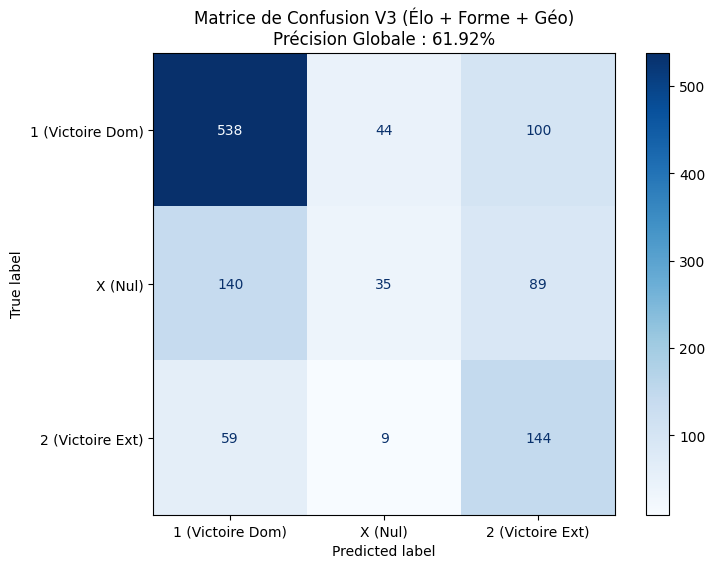

In [11]:
print("📊 Lancement de l'évaluation du modèle de Poisson V3...")

# =====================================================================
# 1. SÉPARATION DES DONNÉES (80% Apprentissage / 20% Test)
# =====================================================================
# On trie par date pour faire un test chronologique réel
df_ml = df_ml.sort_values('date').reset_index(drop=True)
split_index = int(len(df_ml) * 0.8)

train_data = df_ml.iloc[:split_index].copy()
test_data = df_ml.iloc[split_index:].copy()

# =====================================================================
# 2. ENTRAÎNEMENT SUR LE PASSÉ (80%) - AVEC TOUTES LES FEATURES
# =====================================================================
# A. L'équipe Domicile
df_dom_train = pd.DataFrame({
    'buts': train_data['home_score'], 'diff_elo': train_data['diff_elo'], 'est_domicile': train_data['vrai_domicile'],
    'diff_momentum_pts': train_data['diff_momentum_pts'], 'diff_momentum_bp': train_data['diff_momentum_bp'], 'diff_momentum_bc': train_data['diff_momentum_bc'],
    'penalite_alt': train_data['penalite_alt_home'], 'choc_thermique': train_data['choc_thermique_home']
})

# B. L'équipe Extérieur
df_ext_train = pd.DataFrame({
    'buts': train_data['away_score'], 'diff_elo': -train_data['diff_elo'], 'est_domicile': 0,
    'diff_momentum_pts': -train_data['diff_momentum_pts'], 'diff_momentum_bp': -train_data['diff_momentum_bp'], 'diff_momentum_bc': -train_data['diff_momentum_bc'],
    'penalite_alt': train_data['penalite_alt_away'], 'choc_thermique': train_data['choc_thermique_away']
})

df_poisson_train = pd.concat([df_dom_train, df_ext_train], ignore_index=True).dropna()

# Entraînement de la V3
formule = "buts ~ diff_elo + est_domicile + diff_momentum_pts + diff_momentum_bp + diff_momentum_bc + penalite_alt + choc_thermique"
modele_eval = smf.poisson(formule, data=df_poisson_train).fit(disp=False)
coefs = modele_eval.params # Extraction des poids pour aller plus vite

# =====================================================================
# 3. PRÉDICTIONS SUR LE FUTUR (20%) - MODE TURBO
# =====================================================================
print(f"🔮 Prédiction instantanée sur {len(test_data)} matchs de test...")

def predire_1x2(row):
    # Calcul mathématique direct des Lambdas (très rapide)
    log_lam_dom = (coefs['Intercept'] + coefs['diff_elo']*row['diff_elo'] + coefs['est_domicile']*row['vrai_domicile'] +
                   coefs['diff_momentum_pts']*row['diff_momentum_pts'] + coefs['diff_momentum_bp']*row['diff_momentum_bp'] +
                   coefs['diff_momentum_bc']*row['diff_momentum_bc'] + coefs['penalite_alt']*row['penalite_alt_home'] +
                   coefs['choc_thermique']*row['choc_thermique_home'])

    log_lam_ext = (coefs['Intercept'] + coefs['diff_elo']*(-row['diff_elo']) +
                   coefs['diff_momentum_pts']*(-row['diff_momentum_pts']) + coefs['diff_momentum_bp']*(-row['diff_momentum_bp']) +
                   coefs['diff_momentum_bc']*(-row['diff_momentum_bc']) + coefs['penalite_alt']*row['penalite_alt_away'] +
                   coefs['choc_thermique']*row['choc_thermique_away'])

    lambda_dom = np.exp(log_lam_dom)
    lambda_ext = np.exp(log_lam_ext)

    # Création de la matrice et probabilités 1X2
    prob_dom = [poisson.pmf(i, lambda_dom) for i in range(10)]
    prob_ext = [poisson.pmf(i, lambda_ext) for i in range(10)]
    matrice = np.outer(prob_dom, prob_ext)

    proba_1 = np.sum(np.tril(matrice, -1))
    proba_X = np.sum(np.diag(matrice))
    proba_2 = np.sum(np.triu(matrice, 1))

    facteur_nul = 1.35
    proba_X_ajustee = proba_X * facteur_nul

    if proba_1 > proba_X_ajustee and proba_1 > proba_2:
        return '1'
    elif proba_2 > proba_1 and proba_2 > proba_X_ajustee:
        return '2'
    else:
        return 'X'

# Prédiction
test_data['prediction'] = test_data.apply(predire_1x2, axis=1)

# Création de la vraie cible propre (1, X ou 2)
conditions = [
    test_data['home_score'] > test_data['away_score'],
    test_data['home_score'] == test_data['away_score']
]
test_data['vrai_resultat'] = np.select(conditions, ['1', 'X'], default='2')

# =====================================================================
# 4. AFFICHAGE DE LA MATRICE DE CONFUSION
# =====================================================================
precision = accuracy_score(test_data['vrai_resultat'], test_data['prediction'])

cm = confusion_matrix(test_data['vrai_resultat'], test_data['prediction'], labels=['1', 'X', '2'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['1 (Victoire Dom)', 'X (Nul)', '2 (Victoire Ext)'])

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title(f"Matrice de Confusion V3 (Élo + Forme + Géo)\nPrécision Globale : {precision:.2%}")
plt.show()

## 12. Back-test : et si on rejouait le Qatar 2022 ?

Le vrai test d'un modèle de prédiction n'est pas sa précision sur des matchs passés, mais sa capacité
à prédire un tournoi qu'il n'a jamais vu. On réentraîne donc le modèle **uniquement sur 2018 → 19 novembre 2022**,
la veille du coup d'envoi, puis on simule le Qatar 1 000 fois.

Deux particularités du Qatar : tous les stades étaient climatisés à 22 °C au niveau de la mer, donc la
géographie se réduit à un seul lieu ; et le momentum y est borné (±10 buts, divisé par 2) pour éviter
qu'une équipe sortie d'une série de cartons ne domine mécaniquement la simulation.

In [12]:
print("🔄 Création du Dataset Machine Learning (Cycle 2018-2022)...")

# =====================================================================
# 1. ASPIRATION ET NETTOYAGE DES DONNÉES
# =====================================================================
url_teams = 'https://www.eloratings.net/en.teams.tsv'
teams_data = pd.read_csv(url_teams, sep='\t', header=None, usecols=[0, 1], names=['code', 'country'])
teams_data['code'] = teams_data['code'].astype(str)

tous_les_matchs = []
for annee in range(2018, 2023):
    url = f'https://www.eloratings.net/{annee}_results.tsv'
    tous_les_matchs.append(pd.read_csv(url, sep='\t', header=None))

matchs_bruts = pd.concat(tous_les_matchs, ignore_index=True)
matchs_bruts = matchs_bruts.rename(columns={
    0: 'year', 1: 'month', 2: 'day', 3: 'code_home', 4: 'code_away',
    5: 'home_score', 6: 'away_score', 7: 'code_tournoi', 8: 'code_lieu',
    9: 'variation_elo_home', 10: 'elo_home', 11: 'elo_away',
    12: 'variation_class_home', 13: 'variation_class_away', 14: 'rang_mondial_home', 15: 'rang_mondial_away'
})

matchs_bruts['date'] = pd.to_datetime(matchs_bruts[['year', 'month', 'day']])
matchs_bruts['code_home'], matchs_bruts['code_away'] = matchs_bruts['code_home'].astype(str), matchs_bruts['code_away'].astype(str)
matchs_bruts['code_lieu'] = matchs_bruts['code_lieu'].fillna('').astype(str)

matchs_traduits = pd.merge(matchs_bruts, teams_data, left_on='code_home', right_on='code', how='left').rename(columns={'country': 'home_team'}).drop(columns=['code'])
matchs_traduits = pd.merge(matchs_traduits, teams_data, left_on='code_away', right_on='code', how='left').rename(columns={'country': 'away_team'}).drop(columns=['code'])
matchs_traduits = pd.merge(matchs_traduits, teams_data, left_on='code_lieu', right_on='code', how='left')

matchs_traduits['pays_hote'] = matchs_traduits['country'].fillna('')
matchs_traduits.loc[matchs_traduits['pays_hote'] == '', 'pays_hote'] = matchs_traduits['home_team']
matchs_traduits = matchs_traduits.drop(columns=['country', 'code'])

df_ml_2022 = matchs_traduits[['date', 'code_tournoi', 'pays_hote', 'home_team', 'away_team', 'home_score', 'away_score', 'elo_home', 'elo_away']].copy()
df_ml_2022 = df_ml_2022.dropna(subset=['home_score', 'away_score'])

# 🚨 COUPERET TEMPOREL : On coupe avant le Qatar
df_ml_2022 = df_ml_2022[df_ml_2022['date'] < '2022-11-20'].copy()

df_ml_2022['diff_elo'] = df_ml_2022['elo_home'] - df_ml_2022['elo_away']
df_ml_2022['vrai_domicile'] = (df_ml_2022['home_team'] == df_ml_2022['pays_hote']).astype(int)

# =====================================================================
# 2. CALCUL DU MOMENTUM SUR LE PASSÉ (Pour l'entraînement)
# =====================================================================
print("🔥 Calcul du Momentum (10 derniers matchs)...")
df_home = df_ml_2022[['date', 'home_team', 'home_score', 'away_score']].rename(columns={'home_team': 'team', 'home_score': 'bp', 'away_score': 'bc'})
df_away = df_ml_2022[['date', 'away_team', 'away_score', 'home_score']].rename(columns={'away_team': 'team', 'away_score': 'bp', 'home_score': 'bc'})

df_long = pd.concat([df_home, df_away]).sort_values(['team', 'date']).reset_index(drop=True)
df_long['pts_match'] = np.select([(df_long['bp'] > df_long['bc']), (df_long['bp'] == df_long['bc'])], [3, 1], default=0)

grouped = df_long.groupby('team')
df_long['pts_10m'] = grouped['pts_match'].transform(lambda x: x.shift(1).rolling(10, min_periods=1).sum()).fillna(0)
df_long['bp_10m'] = grouped['bp'].transform(lambda x: x.shift(1).rolling(10, min_periods=1).sum()).fillna(0)
df_long['bc_10m'] = grouped['bc'].transform(lambda x: x.shift(1).rolling(10, min_periods=1).sum()).fillna(0)

df_features = df_long[['date', 'team', 'pts_10m', 'bp_10m', 'bc_10m']]

df_ml_2022 = pd.merge(df_ml_2022, df_features, left_on=['date', 'home_team'], right_on=['date', 'team'], how='left').rename(columns={'pts_10m': 'home_pts', 'bp_10m': 'home_bp', 'bc_10m': 'home_bc'}).drop(columns=['team'])
df_ml_2022 = pd.merge(df_ml_2022, df_features, left_on=['date', 'away_team'], right_on=['date', 'team'], how='left').rename(columns={'pts_10m': 'away_pts', 'bp_10m': 'away_bp', 'bc_10m': 'away_bc'}).drop(columns=['team'])
df_ml_2022 = df_ml_2022.fillna(0)

df_ml_2022['diff_momentum_pts'] = df_ml_2022['home_pts'] - df_ml_2022['away_pts']
df_ml_2022['diff_momentum_bp'] = df_ml_2022['home_bp'] - df_ml_2022['away_bp']
df_ml_2022['diff_momentum_bc'] = df_ml_2022['home_bc'] - df_ml_2022['away_bc']

df_ml_2022['year'] = df_ml_2022['date'].dt.year

# Altitude
df_ml_2022['alt_stade'] = df_ml_2022['pays_hote'].map(dict_altitude).fillna(100.0)
df_ml_2022['alt_habituelle_home'] = df_ml_2022['home_team'].map(dict_altitude).fillna(100.0)
df_ml_2022['alt_habituelle_away'] = df_ml_2022['away_team'].map(dict_altitude).fillna(100.0)

df_ml_2022['penalite_alt_home'] = np.maximum(0, df_ml_2022['alt_stade'] - df_ml_2022['alt_habituelle_home']) / 1000
df_ml_2022['penalite_alt_away'] = np.maximum(0, df_ml_2022['alt_stade'] - df_ml_2022['alt_habituelle_away']) / 1000

# Température (On utilise le dictionnaire 'derniere_temp_connue' qu'on a créé avant)
df_ml_2022['temp_stade'] = df_ml_2022['pays_hote'].map(derniere_temp_connue).fillna(20.0)
df_ml_2022['temp_habituelle_home'] = df_ml_2022['home_team'].map(derniere_temp_connue).fillna(20.0)
df_ml_2022['temp_habituelle_away'] = df_ml_2022['away_team'].map(derniere_temp_connue).fillna(20.0)

df_ml_2022['choc_thermique_home'] = np.abs(df_ml_2022['temp_stade'] - df_ml_2022['temp_habituelle_home'])
df_ml_2022['choc_thermique_away'] = np.abs(df_ml_2022['temp_stade'] - df_ml_2022['temp_habituelle_away'])

# =====================================================================
# 2. ENTRAÎNEMENT DU MODÈLE V3 (Jusqu'en Nov 2022)
# =====================================================================
print("🚀 Entraînement de l'IA sur les données pré-Qatar...")

df_dom_22 = pd.DataFrame({
    'buts': df_ml_2022['home_score'], 'diff_elo': df_ml_2022['diff_elo'], 'est_domicile': df_ml_2022['vrai_domicile'],
    'diff_momentum_pts': df_ml_2022['diff_momentum_pts'], 'diff_momentum_bp': df_ml_2022['diff_momentum_bp'], 'diff_momentum_bc': df_ml_2022['diff_momentum_bc'],
    'penalite_alt': df_ml_2022['penalite_alt_home'], 'choc_thermique': df_ml_2022['choc_thermique_home']
})

df_ext_22 = pd.DataFrame({
    'buts': df_ml_2022['away_score'], 'diff_elo': -df_ml_2022['diff_elo'], 'est_domicile': 0,
    'diff_momentum_pts': -df_ml_2022['diff_momentum_pts'], 'diff_momentum_bp': -df_ml_2022['diff_momentum_bp'], 'diff_momentum_bc': -df_ml_2022['diff_momentum_bc'],
    'penalite_alt': df_ml_2022['penalite_alt_away'], 'choc_thermique': df_ml_2022['choc_thermique_away']
})

df_poisson_2022 = pd.concat([df_dom_22, df_ext_22], ignore_index=True).dropna()
formule = "buts ~ diff_elo + est_domicile + diff_momentum_pts + diff_momentum_bp + diff_momentum_bc + penalite_alt + choc_thermique"
model_poisson_2022 = smf.poisson(formule, data=df_poisson_2022).fit(disp=False)
coefs_2022 = model_poisson_2022.params # Extraction Turbo

# =====================================================================
# 4. EXTRACTION DES DICTIONNAIRES "LIVE" (Novembre 2022)
# =====================================================================
print("📸 Création des Dictionnaires (Elo et Momentum) à la veille de Qatar 2022...")

# A. Dictionnaire Elo
# L'Elo de chaque sélection à la veille du Qatar est déduit des matchs déjà téléchargés :
# chaque ligne de eloratings.net porte l'Elo d'avant-match des deux équipes, il suffit donc
# de retenir la dernière valeur connue avant le 20 novembre 2022.
elo_long = pd.concat([
    df_ml_2022[['date', 'home_team', 'elo_home']].rename(columns={'home_team': 'team', 'elo_home': 'rating'}),
    df_ml_2022[['date', 'away_team', 'elo_away']].rename(columns={'away_team': 'team', 'elo_away': 'rating'}),
]).dropna().sort_values('date')
dict_elo_2022_precis = elo_long.groupby('team').tail(1).set_index('team')['rating'].to_dict()
print(f"📸 Elo au 19/11/2022 reconstitué pour {len(dict_elo_2022_precis)} sélections.")

# B. Dictionnaire Momentum
derniers_matchs_2022 = df_long.groupby('team').tail(10)
stats_live_2022 = derniers_matchs_2022.groupby('team').agg({'pts_match': 'sum', 'bp': 'sum', 'bc': 'sum'}).rename(columns={'pts_match': 'pts'}).reset_index()
dict_momentum_2022 = stats_live_2022.set_index('team').to_dict('index')

print(model_poisson_2022.summary())

# =====================================================================
# 5. FONCTIONS DE SIMULATION (Intégration du Momentum)
# =====================================================================
def simuler_match_elimination_2022(eq1, eq2, dict_elo, dict_momentum, dict_geo, coefs, pays_hotes):
    elo1, elo2 = dict_elo.get(eq1, 1500), dict_elo.get(eq2, 1500)
    mom1, mom2 = dict_momentum.get(eq1, {'pts': 0, 'bp': 0, 'bc': 0}), dict_momentum.get(eq2, {'pts': 0, 'bp': 0, 'bc': 0})

    hote1 = 1 if eq1 in pays_hotes else 0
    hote2 = 1 if eq2 in pays_hotes else 0

    pen_1, choc_1 = calculer_fardeau_physique_2022(eq1, dict_geo)
    pen_2, choc_2 = calculer_fardeau_physique_2022(eq2, dict_geo)

    d_pts, d_bp, d_bc = mom1['pts'] - mom2['pts'], mom1['bp'] - mom2['bp'], mom1['bc'] - mom2['bc']
    d_bp_cap = max(-10, min(10, d_bp))
    d_bc_cap = max(-10, min(10, d_bc))
    d_bp = d_bp_cap / 2.0
    d_bc = d_bc_cap / 2.0

    log_lam_1 = (coefs['Intercept'] + coefs['diff_elo']*(elo1-elo2) + coefs['est_domicile']*hote1 +
                 coefs['diff_momentum_pts']*d_pts + coefs['diff_momentum_bp']*d_bp + coefs['diff_momentum_bc']*d_bc +
                 coefs['penalite_alt']*pen_1 + coefs['choc_thermique']*choc_1)

    log_lam_2 = (coefs['Intercept'] + coefs['diff_elo']*(elo2-elo1) + coefs['est_domicile']*hote2 +
                 coefs['diff_momentum_pts']*(-d_pts) + coefs['diff_momentum_bp']*(-d_bp) + coefs['diff_momentum_bc']*(-d_bc) +
                 coefs['penalite_alt']*pen_2 + coefs['choc_thermique']*choc_2)

    l1, l2 = np.exp(log_lam_1), np.exp(log_lam_2)

    b1, b2 = np.random.poisson(l1), np.random.poisson(l2)
    if b1 > b2: return eq1
    if b2 > b1: return eq2

    if (b1 + np.random.poisson(l1/3)) > (b2 + np.random.poisson(l2/3)): return eq1
    if (b2 + np.random.poisson(l2/3)) > (b1 + np.random.poisson(l1/3)): return eq2

    return eq1 if np.random.rand() < (1 / (1 + 10 ** ((elo2 - elo1) / 400))) else eq2

def simuler_un_univers_2022(groupes, dict_elo, dict_momentum, dict_geo, coefs, pays_hotes):
    premiers, deuxiemes = [], []

    # --- POULES ---
    for nom_groupe, equipes in groupes.items():
        classement = {eq: {'pts': 0, 'diff': 0, 'bp': 0} for eq in equipes}

        for eq1, eq2 in combinations(equipes, 2):
            e1, e2 = dict_elo.get(eq1, 1500), dict_elo.get(eq2, 1500)
            m1, m2 = dict_momentum.get(eq1, {'pts': 0, 'bp': 0, 'bc': 0}), dict_momentum.get(eq2, {'pts': 0, 'bp': 0, 'bc': 0})
            h1 = 1 if eq1 in pays_hotes else 0
            h2 = 1 if eq2 in pays_hotes else 0

            p1, c1 = calculer_fardeau_physique_2022(eq1, dict_geo)
            p2, c2 = calculer_fardeau_physique_2022(eq2, dict_geo)

            d_pts, d_bp, d_bc = m1['pts'] - m2['pts'], m1['bp'] - m2['bp'], m1['bc'] - m2['bc']
            d_bp_cap = max(-10, min(10, d_bp))
            d_bc_cap = max(-10, min(10, d_bc))
            d_bp = d_bp_cap / 2.0
            d_bc = d_bc_cap / 2.0

            l1 = np.exp(coefs['Intercept'] + coefs['diff_elo']*(e1-e2) + coefs['est_domicile']*h1 +
                        coefs['diff_momentum_pts']*d_pts + coefs['diff_momentum_bp']*d_bp + coefs['diff_momentum_bc']*d_bc +
                        coefs['penalite_alt']*p1 + coefs['choc_thermique']*c1)
            l2 = np.exp(coefs['Intercept'] + coefs['diff_elo']*(e2-e1) + coefs['est_domicile']*h2 +
                        coefs['diff_momentum_pts']*(-d_pts) + coefs['diff_momentum_bp']*(-d_bp) + coefs['diff_momentum_bc']*(-d_bc) +
                        coefs['penalite_alt']*p2 + coefs['choc_thermique']*c2)

            b1, b2 = np.random.poisson(l1), np.random.poisson(l2)
            classement[eq1]['bp'] += b1; classement[eq1]['diff'] += (b1 - b2)
            classement[eq2]['bp'] += b2; classement[eq2]['diff'] += (b2 - b1)

            if b1 > b2: classement[eq1]['pts'] += 3
            elif b2 > b1: classement[eq2]['pts'] += 3
            else: classement[eq1]['pts'] += 1; classement[eq2]['pts'] += 1

        trie = sorted(classement.items(), key=lambda x: (x[1]['pts'], x[1]['diff'], x[1]['bp']), reverse=True)
        premiers.append(trie[0][0])
        deuxiemes.append(trie[1][0])

    # --- L'ARBRE EXACT DE LA FIFA 2022 (32 Équipes) ---
    # Indices : A=0, B=1, C=2, D=3, E=4, F=5, G=6, H=7
    huitiemes_matchs = [
        (premiers[0], deuxiemes[1]), # 1A vs 2B
        (premiers[2], deuxiemes[3]), # 1C vs 2D
        (premiers[4], deuxiemes[5]), # 1E vs 2F
        (premiers[6], deuxiemes[7]), # 1G vs 2H
        (premiers[1], deuxiemes[0]), # 1B vs 2A
        (premiers[3], deuxiemes[2]), # 1D vs 2C
        (premiers[5], deuxiemes[4]), # 1F vs 2E
        (premiers[7], deuxiemes[6])  # 1H vs 2G
    ]

    huit = [simuler_match_elimination_2022(m[0], m[1], dict_elo, dict_momentum, dict_geo, coefs, pays_hotes) for m in huitiemes_matchs]

    quarts_matchs = [(huit[0], huit[1]), (huit[2], huit[3]), (huit[4], huit[5]), (huit[6], huit[7])]
    quarts = [simuler_match_elimination_2022(m[0], m[1], dict_elo, dict_momentum, dict_geo, coefs, pays_hotes) for m in quarts_matchs]

    demies_matchs = [(quarts[0], quarts[1]), (quarts[2], quarts[3])]
    demies = [simuler_match_elimination_2022(m[0], m[1], dict_elo, dict_momentum, dict_geo, coefs, pays_hotes) for m in demies_matchs]

    fin = [demies[0], demies[1]]
    champion = simuler_match_elimination_2022(fin[0], fin[1], dict_elo, dict_momentum, dict_geo, coefs, pays_hotes)

    return huit, quarts, demies, fin, champion

# =====================================================================
# 5. BOUCLE MONTE-CARLO
# =====================================================================
def lancer_monte_carlo_2022(groupes, dict_elo, dict_momentum, dict_geo, coefs, pays_hotes, nb_simus=1000):
    print(f"🚀 Lancement de {nb_simus} simulations QATAR 2022 (MODE TURBO)...")

    tracker = defaultdict(lambda: {'8es': 0, 'Quarts': 0, 'Demies': 0, 'Finale': 0, 'Sacre': 0})

    for i in range(nb_simus):
        if i % 250 == 0 and i > 0: print(f"   ... {i} univers explorés ...")

        huit, quarts, demies, fin, vainqueur = simuler_un_univers_2022(groupes, dict_elo, dict_momentum, dict_geo, coefs, pays_hotes)

        for eq in huit: tracker[eq]['8es'] += 1
        for eq in quarts: tracker[eq]['Quarts'] += 1
        for eq in demies: tracker[eq]['Demies'] += 1
        for eq in fin: tracker[eq]['Finale'] += 1
        tracker[vainqueur]['Sacre'] += 1

    print("\n🏆 CHANCES DE GAGNER LA COUPE DU MONDE 2022 🏆")
    print("=" * 65)
    print(f"{'Équipe':<15} | 8es   | Quarts | Demies | Finale | 🏆 SACRE")
    print("-" * 65)

    resultats_tries = sorted(tracker.items(), key=lambda x: x[1]['Sacre'], reverse=True)

    for eq, stats in resultats_tries:
        if stats['Sacre'] > 0:
            print(f"{eq:<15} | {(stats['8es']/nb_simus)*100:>4.0f}% | {(stats['Quarts']/nb_simus)*100:>5.0f}% | {(stats['Demies']/nb_simus)*100:>5.0f}% | {(stats['Finale']/nb_simus)*100:>5.0f}% | {(stats['Sacre']/nb_simus)*100:>5.1f}%")
# =====================================================================
# 6. LANCEMENT DU BACKTEST QATAR 2022
# =====================================================================
groupes_2022 = {
    'Groupe A': ['Qatar', 'Ecuador', 'Senegal', 'Netherlands'],
    'Groupe B': ['England', 'Iran', 'United States', 'Wales'],
    'Groupe C': ['Argentina', 'Saudi Arabia', 'Mexico', 'Poland'],
    'Groupe D': ['France', 'Australia', 'Denmark', 'Tunisia'],
    'Groupe E': ['Spain', 'Costa Rica', 'Germany', 'Japan'],
    'Groupe F': ['Belgium', 'Canada', 'Morocco', 'Croatia'],
    'Groupe G': ['Brazil', 'Serbia', 'Switzerland', 'Cameroon'],
    'Groupe H': ['Portugal', 'Ghana', 'Uruguay', 'South Korea']
}
print("🌍 Création du Dictionnaire Géographique 2022...")

dict_geo_equipes_2022 = {}

# On rassemble les 32 équipes du Qatar
toutes_les_equipes_2022 = [eq for poule in groupes_2022.values() for eq in poule]

for equipe in toutes_les_equipes_2022:
    # Sécurité absolue : on utilise 'globals()' pour vérifier si les données météo sont bien en mémoire
    alt = dict_altitude.get(equipe, 100.0) if 'dict_altitude' in globals() else 100.0
    temp = derniere_temp_connue.get(equipe, 20.0) if 'derniere_temp_connue' in globals() else 20.0

    dict_geo_equipes_2022[equipe] = {'alt': alt, 'temp': temp}

print(f"✅ Dictionnaire créé avec succès pour {len(dict_geo_equipes_2022)} équipes !")

# Le Qatar a climatisé tous ses stades à 22°C, au niveau de la mer.
stades_2022 = {'Doha (AC)': {'alt': 10, 'temp': 22}}

def calculer_fardeau_physique_2022(equipe, dict_geo):
    eq_alt = dict_geo.get(equipe, {'alt': 100})['alt']
    eq_temp = dict_geo.get(equipe, {'temp': 20})['temp']
    pen_alt = max(0, 10 - eq_alt) / 1000.0 # 10m = Altitude de Doha
    choc_therm = abs(22 - eq_temp)         # 22°C = Température des stades
    return pen_alt, choc_therm

pays_hotes_2022 = ['Qatar']

lancer_monte_carlo_2022(
    groupes=groupes_2022,
    dict_elo=dict_elo_2022_precis,
    dict_momentum=dict_momentum_2022,
    dict_geo=dict_geo_equipes_2022,
    coefs=coefs_2022,
    pays_hotes=pays_hotes_2022,
    nb_simus=1000
)

🔄 Création du Dataset Machine Learning (Cycle 2018-2022)...
🔥 Calcul du Momentum (10 derniers matchs)...
🚀 Entraînement de l'IA sur les données pré-Qatar...
📸 Création des Dictionnaires (Elo et Momentum) à la veille de Qatar 2022...
📸 Elo au 19/11/2022 reconstitué pour 228 sélections.
                          Poisson Regression Results                          
Dep. Variable:                   buts   No. Observations:                 8862
Model:                        Poisson   Df Residuals:                     8854
Method:                           MLE   Df Model:                            7
Date:                Wed, 18 Nov 2026   Pseudo R-squ.:                  0.1590
Time:                        04:11:07   Log-Likelihood:                -12069.
converged:                       True   LL-Null:                       -14350.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                        coef    std err          z      P>|z|      [0.025      0.9

## 13. Le bulletin de notes

Dernière étape : comparer les deux qualifiés prédits dans chaque groupe du Qatar aux seize équipes
réellement sorties de poules. Ici on ne tire plus de score au hasard — on retient le score le plus
probable, pour que le verdict soit reproductible.

In [13]:
# =====================================================================
# 1. LA VÉRITÉ HISTORIQUE (Les vrais qualifiés de 2022)
# =====================================================================
vrais_qualifies_2022 = {
    'Groupe A': ['Netherlands', 'Senegal'],
    'Groupe B': ['England', 'United States'],
    'Groupe C': ['Argentina', 'Poland'],
    'Groupe D': ['France', 'Australia'],
    'Groupe E': ['Japan', 'Spain'], # L'Allemagne a été éliminée !
    'Groupe F': ['Morocco', 'Croatia'], # La Belgique a été éliminée !
    'Groupe G': ['Brazil', 'Switzerland'],
    'Groupe H': ['Portugal', 'South Korea'] # L'Uruguay a été éliminée !
}

# =====================================================================
# 1.bis VERSION DÉTERMINISTE DE LA SIMULATION
# =====================================================================
# Pendant exact de la simulation Monte-Carlo : au lieu de TIRER un score dans la loi de
# Poisson, on retient le score exact le plus probable (argmax de la matrice des
# probabilités). Mêmes 7 variables, résultat reproductible d'une exécution à l'autre.

def obtenir_score_le_plus_probable(eq1, eq2, dict_elo, dict_momentum, dict_geo,
                                   coefs, pays_hotes, max_buts=10):
    elo1, elo2 = dict_elo.get(eq1, 1500), dict_elo.get(eq2, 1500)
    mom1 = dict_momentum.get(eq1, {'pts': 0, 'bp': 0, 'bc': 0})
    mom2 = dict_momentum.get(eq2, {'pts': 0, 'bp': 0, 'bc': 0})

    hote1 = 1 if eq1 in pays_hotes else 0
    hote2 = 1 if eq2 in pays_hotes else 0

    pen_1, choc_1 = calculer_fardeau_physique_2022(eq1, dict_geo)
    pen_2, choc_2 = calculer_fardeau_physique_2022(eq2, dict_geo)

    # Même bornage du momentum que dans la simulation du Qatar
    d_pts = mom1['pts'] - mom2['pts']
    d_bp = max(-10, min(10, mom1['bp'] - mom2['bp'])) / 2.0
    d_bc = max(-10, min(10, mom1['bc'] - mom2['bc'])) / 2.0

    lam1 = np.exp(coefs['Intercept'] + coefs['diff_elo'] * (elo1 - elo2) + coefs['est_domicile'] * hote1 +
                  coefs['diff_momentum_pts'] * d_pts + coefs['diff_momentum_bp'] * d_bp + coefs['diff_momentum_bc'] * d_bc +
                  coefs['penalite_alt'] * pen_1 + coefs['choc_thermique'] * choc_1)
    lam2 = np.exp(coefs['Intercept'] + coefs['diff_elo'] * (elo2 - elo1) + coefs['est_domicile'] * hote2 +
                  coefs['diff_momentum_pts'] * (-d_pts) + coefs['diff_momentum_bp'] * (-d_bp) + coefs['diff_momentum_bc'] * (-d_bc) +
                  coefs['penalite_alt'] * pen_2 + coefs['choc_thermique'] * choc_2)

    matrice = np.outer([poisson.pmf(i, lam1) for i in range(max_buts)],
                       [poisson.pmf(i, lam2) for i in range(max_buts)])
    b1, b2 = np.unravel_index(np.argmax(matrice), matrice.shape)
    return int(b1), int(b2)

# =====================================================================
# 2. LA FONCTION D'ÉVALUATION DU MODÈLE
# =====================================================================
def evaluer_predictions_2022(groupes, dict_elo, dict_momentum, dict_geo, coefs, pays_hotes, vrais_resultats):
    print("📊 ÉVALUATION DE TON MODÈLE VS RÉALITÉ (QATAR 2022) 📊\n")
    print("=" * 65)

    total_bonnes_predictions = 0
    total_equipes = 16 # 8 groupes * 2 qualifiés

    for nom_groupe, equipes in groupes.items():

        # --- A. On fait jouer le groupe (Logique pure, sans hasard) ---
        classement = {eq: {'pts': 0, 'diff': 0, 'bp': 0} for eq in equipes}
        matchs_poule = list(combinations(equipes, 2))

        for eq1, eq2 in matchs_poule:
            elo1 = dict_elo.get(eq1, 1500)
            elo2 = dict_elo.get(eq2, 1500)
            eq1_hote = eq1 in pays_hotes
            eq2_hote = eq2 in pays_hotes

            # Appel de la fonction de score exact (qu'on a définie avant)
            buts_1, buts_2 = obtenir_score_le_plus_probable(
                eq1, eq2, dict_elo, dict_momentum, dict_geo, coefs, pays_hotes)

            classement[eq1]['bp'] += buts_1
            classement[eq1]['diff'] += (buts_1 - buts_2)
            classement[eq2]['bp'] += buts_2
            classement[eq2]['diff'] += (buts_2 - buts_1)

            if buts_1 > buts_2:
                classement[eq1]['pts'] += 3
            elif buts_1 < buts_2:
                classement[eq2]['pts'] += 3
            else:
                classement[eq1]['pts'] += 1
                classement[eq2]['pts'] += 1

        # --- B. On extrait tes 2 qualifiés ---
        classement_trie = sorted(
            classement.items(),
            key=lambda x: (x[1]['pts'], x[1]['diff'], x[1]['bp']),
            reverse=True
        )
        qualifies_predits = [classement_trie[0][0], classement_trie[1][0]]

        # --- C. On compare avec l'Histoire ---
        vrais_qualifies_du_groupe = vrais_resultats[nom_groupe]

        # L'utilisation des "set" permet de vérifier les équipes sans se soucier de l'ordre (1er ou 2ème)
        bonnes_reponses = set(qualifies_predits).intersection(set(vrais_qualifies_du_groupe))
        nb_bonnes = len(bonnes_reponses)
        total_bonnes_predictions += nb_bonnes

        pourcentage_groupe = (nb_bonnes / 2) * 100

        # --- D. Affichage du bulletin de notes ---
        print(f"🏆 {nom_groupe.upper()} - Précision : {pourcentage_groupe:.0f}%")
        print(f"   Vrais qualifiés  : {', '.join(vrais_qualifies_du_groupe)}")
        print(f"   Tes prédictions  : {', '.join(qualifies_predits)}")

        if nb_bonnes == 2:
            print("   ✅ Carton plein !")
        elif nb_bonnes == 1:
            print("   ⚠️ 1 sur 2 (Une surprise a déjoué la logique !)")
        else:
            print("   ❌ Tout faux (Chaos total dans ce groupe !)")
        print("-" * 40)

    # --- 3. NOTE GLOBALE ---
    precision_globale = (total_bonnes_predictions / total_equipes) * 100
    print("=" * 65)
    print(f"🎯 PRÉCISION GLOBALE DE TON MODÈLE : {precision_globale:.1f}% ({total_bonnes_predictions}/16 équipes trouvées)")
    print("=" * 65)

    if precision_globale > 70:
        print("C'est un score ÉLITE ! Ton modèle capte remarquablement la hiérarchie mondiale.")
    elif precision_globale >= 50:
        print("Score correct. Le modèle lit bien les favoris, mais la folie du Qatar t'a coûté des points.")
    else:
        print("Aïe. Le modèle est trop rigide, ou le Qatar était beaucoup trop chaotique !")

# =====================================================================
# 3. LANCEMENT DU TEST
# =====================================================================
evaluer_predictions_2022(
    groupes=groupes_2022,
    dict_elo=dict_elo_2022_precis,
    dict_momentum=dict_momentum_2022,
    dict_geo=dict_geo_equipes_2022,
    coefs=coefs_2022,
    pays_hotes=pays_hotes_2022,
    vrais_resultats=vrais_qualifies_2022
)

📊 ÉVALUATION DE TON MODÈLE VS RÉALITÉ (QATAR 2022) 📊

🏆 GROUPE A - Précision : 50%
   Vrais qualifiés  : Netherlands, Senegal
   Tes prédictions  : Netherlands, Ecuador
   ⚠️ 1 sur 2 (Une surprise a déjoué la logique !)
----------------------------------------
🏆 GROUPE B - Précision : 50%
   Vrais qualifiés  : England, United States
   Tes prédictions  : England, Wales
   ⚠️ 1 sur 2 (Une surprise a déjoué la logique !)
----------------------------------------
🏆 GROUPE C - Précision : 50%
   Vrais qualifiés  : Argentina, Poland
   Tes prédictions  : Argentina, Mexico
   ⚠️ 1 sur 2 (Une surprise a déjoué la logique !)
----------------------------------------
🏆 GROUPE D - Précision : 50%
   Vrais qualifiés  : France, Australia
   Tes prédictions  : France, Denmark
   ⚠️ 1 sur 2 (Une surprise a déjoué la logique !)
----------------------------------------
🏆 GROUPE E - Précision : 50%
   Vrais qualifiés  : Japan, Spain
   Tes prédictions  : Spain, Germany
   ⚠️ 1 sur 2 (Une surprise a déjou

## 14. Rétrospective : le tournoi a eu lieu

Le modèle ne connaît rien de ce qui s'est passé après le 5 juin 2026. La Coupe du Monde s'est jouée
depuis : **l'Espagne a battu l'Argentine 1-0 après prolongation** en finale, le 19 juillet au MetLife
Stadium, pour son deuxième titre mondial.

On peut donc faire ce qu'aucune métrique de validation ne remplace : confronter les probabilités de la
section 10 au déroulé réel du tournoi. La cellule ci-dessous note directement la sortie de cette
exécution — rien n'est recopié à la main.

Attention à la lecture : un modèle qui annonce l'Espagne autour de 30 % et la voit gagner n'a pas « eu
raison ». Il a dit qu'elle gagnerait environ une fois sur trois, et c'est arrivé. Un seul tournoi ne
départage jamais un bon modèle d'un modèle chanceux — d'où le score de Brier, qui évalue la
distribution entière plutôt que le seul vainqueur.

In [14]:
# Ce qui s'est réellement passé
QUARTS_REELS = ['Spain', 'Argentina', 'France', 'England', 'Belgium', 'Switzerland', 'Norway', 'Morocco']
DEMIES_REELLES = ['Spain', 'Argentina', 'France', 'England']   # Spain 2-0 France, Argentina 2-1 England
FINALISTES_REELS = ['Spain', 'Argentina']                       # Spain 1-0 Argentina (a.p.)
CHAMPION_REEL = 'Spain'

# Les probabilités notées sont celles produites par la section 10 de CETTE exécution
PHASES = {'quarts': 'Quarts', 'demies': 'Demies', 'finale': 'Finale', 'titre': 'Sacre'}
NB_EQUIPES = sum(len(v) for v in groupes_2026.values())

def proba(phase, equipe):
    return probas_2026.get(equipe, {}).get(PHASES[phase], 0.0)

def rang(phase, equipe):
    """Rang de l'équipe dans le classement du modèle pour cette phase (ex aequo = même rang)."""
    p = proba(phase, equipe)
    return 1 + sum(1 for eq in probas_2026 if proba(phase, eq) > p)

def bulletin(phase, reels):
    print(f"\n{phase.upper()} — {len(reels)} équipes qualifiées")
    print(f"{'Équipe':<14} | {'Proba modèle':>12} | {'Rang':>5}")
    print('-' * 38)
    for eq in sorted(reels, key=lambda e: -proba(phase, e)):
        print(f"{eq:<14} | {proba(phase, eq):>11.0%} | {rang(phase, eq):>5}")

print('🔍 LE MODÈLE FACE À LA RÉALITÉ')
print('=' * 38)
bulletin('quarts', QUARTS_REELS)
bulletin('demies', DEMIES_REELLES)
bulletin('finale', FINALISTES_REELS)

print(f"\n🏆 CHAMPION : {CHAMPION_REEL} — annoncé à {proba('titre', CHAMPION_REEL):.1%}, "
      f"rang {rang('titre', CHAMPION_REEL)} du modèle")

# Score de Brier sur le titre : on évalue la distribution entière, pas le seul vainqueur.
brier = sum((proba('titre', eq) - (1 if eq == CHAMPION_REEL else 0)) ** 2
            for eq in [e for poule in groupes_2026.values() for e in poule])
brier_uniforme = (1 - 1 / NB_EQUIPES) ** 2 + (NB_EQUIPES - 1) * (1 / NB_EQUIPES) ** 2

print(f"\n📐 Score de Brier (titre, {NB_EQUIPES} équipes, plus bas = mieux)")
print(f"   Modèle              : {brier:.3f}")
print(f"   Référence uniforme  : {brier_uniforme:.3f}")
print(f"   Amélioration        : {100 * (1 - brier / brier_uniforme):.0f}%")

🔍 LE MODÈLE FACE À LA RÉALITÉ

QUARTS — 8 équipes qualifiées
Équipe         | Proba modèle |  Rang
--------------------------------------
Spain          |         69% |     1
Argentina      |         57% |     2
England        |         45% |     5
France         |         42% |     6
Switzerland    |         32% |    10
Norway         |         27% |    12
Belgium        |         24% |    15
Morocco        |         19% |    19

DEMIES — 4 équipes qualifiées
Équipe         | Proba modèle |  Rang
--------------------------------------
Spain          |         51% |     1
Argentina      |         38% |     2
France         |         24% |     5
England        |         21% |     6

FINALE — 2 équipes qualifiées
Équipe         | Proba modèle |  Rang
--------------------------------------
Spain          |         40% |     1
Argentina      |         29% |     2

🏆 CHAMPION : Spain — annoncé à 28.0%, rang 1 du modèle

📐 Score de Brier (titre, 48 équipes, plus bas = mieux)
   Modèle       